# IT9002 Natural Language Processing — Individual Project
## Notebook 2 of 3: Task 2 — Clause extraction from whole contracts (Option A, sequence labelling)

**Student:** see the setup cell (reads `project_info.json`) · **Course:** IT9002 Natural Language Processing

**Dataset:** Contract Understanding Atticus Dataset (CUAD) v1 — https://www.atticusprojectai.org/cuad
(data and code: https://github.com/TheAtticusProject/cuad), licence CC BY 4.0.

| Section | Content | Rubric |
|---|---|---|
| 1 | Purpose and link to Task 1 | Task 2 |
| 2 | Data in the required format: windows, token labels, decoder, **oracle check** | Task 2 data; Part A preprocessing |
| 3 | Evaluation code (entity-level P/R/F1, CUAD-style AUPR) and its tests | Task 2 evaluation; Part C metrics |
| 4 | Baseline: TF-IDF segment classifier | Task 2 model |
| 5 | Main model: Legal-BERT token tagger | Task 2 model |
| 6 | Test evaluation (once per model) | Task 2 evaluation; objective O4 |
| 7 | Published comparison with the CUAD paper | Part C |
| 8 | Representative outputs and error analysis | Task 2 outputs; Part C error analysis |
| 9 | DEMO: extract clauses from any contract text | video |
| 10 | Conclusion and limitations | Part C |

### How to run
Locally: open the notebook from the project folder with the `.venv` environment and *Run All*. On Google Colab the setup
cell downloads the code and data from GitHub. Heavy steps have switches (`RETRAIN`, `RUN_SEARCH`): with `False` the saved
results of the real run are used, so the notebook re-runs in minutes; the tagger's test predictions need the saved model
weights (`models/`, not in the repository) — without them the saved predicted spans are loaded and the notebook says so.

## ▶ Run on Google Colab (skip this on your own computer)
**For markers using Google Colab.** Runtime → Change runtime type → **GPU** (T4 is enough), then Runtime → **Run all**.
The cell below gets the project — from the GitHub repository if its URL is set, otherwise from the submission ZIP uploaded
to Google Drive (default `MyDrive/IT9002_202609212.zip`; change `ZIP_PATH` if it is elsewhere) — installs the pinned
packages and moves into the project folder. On your own computer it does nothing. Colab starts without the trained models
(`models/`, too large to share), so cells that need them print **SKIPPED** with retraining instructions and then show the
outputs those cells produced in the real run (tables, figures, text, labelled SAVED); the DEMO sections do the same.

In [1]:
# ==== RUN ON GOOGLE COLAB - does nothing on your own computer ====
import os, sys, subprocess, zipfile
from pathlib import Path
SIMULATE = os.environ.get("IT9002_SIMULATE_COLAB") == "1"         # local test of the Colab path
IN_COLAB = "google.colab" in sys.modules or SIMULATE
GITHUB_URL = "https://github.com/202609212-AbdullaAlhermi/IT9002-202609212-Project"                             # the project's GitHub repository (as in project_info.json)
ZIP_PATH = "/content/drive/MyDrive/IT9002_202609212.zip"           # used when the repository cannot be cloned

def find_root(start):
    """The project folder = the first folder, going upwards, that contains project_info.json."""
    return next((d for d in [start, *start.parents] if (d / "project_info.json").exists()), None)

if IN_COLAB:
    base = Path(os.environ.get("IT9002_COLAB_BASE", "/content"))
    root = find_root(Path.cwd())
    if root is None and GITHUB_URL.startswith("https://github.com/"):            # a) clone the repository
        clone = base / "IT9002_project"
        if not clone.exists():
            # no password prompt: a private repository simply fails here and the ZIP route below is used instead
            r = subprocess.run(["git", "-c", "credential.helper=", "clone", "--depth", "1", GITHUB_URL, str(clone)],
                               env=dict(os.environ, GIT_TERMINAL_PROMPT="0"), capture_output=True, text=True)
            if r.returncode != 0:
                print("Could not clone the repository (it may be private); using the submission ZIP from Google Drive.")
        root = clone if (clone / "project_info.json").exists() else None
    if root is None:                                                             # b) unzip the submission ZIP from Drive
        if not SIMULATE:
            from google.colab import drive
            drive.mount("/content/drive")
        zp = Path(os.environ.get("IT9002_COLAB_ZIP", ZIP_PATH))
        assert zp.exists(), f"Upload the submission ZIP to Google Drive and set ZIP_PATH (not found: {zp})"
        with zipfile.ZipFile(zp) as z:
            root = base / z.namelist()[0].split("/")[0]
            if not root.exists():
                z.extractall(base)
    os.chdir(root / "notebooks")
    # pinned requirements, but keep Colab's own CUDA build of torch and its Jupyter packages
    keep = ("torch", "jupyterlab", "ipykernel", "nbformat", "nbconvert", "nbclient")
    reqs = [l.strip() for l in (root / "requirements.txt").read_text().splitlines()
            if l.strip() and not l.startswith("#") and not l.split("==")[0].strip().lower().startswith(keep)]
    (root / "requirements_colab.txt").write_text("\n".join(reqs) + "\n")
    loaded = {m: sys.modules[m].__version__ for m in ("numpy", "pandas", "scipy", "sklearn") if m in sys.modules}
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(root / "requirements_colab.txt")]
                   + (["--dry-run"] if SIMULATE else []), check=True)
    pins = dict(l.split("==") for l in reqs if "==" in l)
    stale = [m for m, v in loaded.items() if pins.get({"sklearn": "scikit-learn"}.get(m, m), v) != v]
    if stale and not SIMULATE:
        raise RuntimeError(f"New versions of {stale} were installed: Runtime -> Restart session, then Run all again.")
    from importlib.metadata import version
    print(f"Colab: project folder {root} | pinned requirements {'checked (dry run)' if SIMULATE else 'installed'} | "
          f"torch {version('torch')} kept")
else:
    print("Not on Colab: nothing to do here.")

Not on Colab: nothing to do here.


## 0. Setup

In [2]:
import sys, os, json, platform, subprocess, importlib, re, time, warnings, contextlib, io
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules or os.environ.get("IT9002_SIMULATE_COLAB") == "1"
# The project folder = the first folder, going upwards, that contains project_info.json (works from notebooks/, from the
# project folder and on Colab, where the cell above has moved into the project).
ROOT = next(d for d in [Path.cwd(), *Path.cwd().parents] if (d / "project_info.json").exists())
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", message="IProgress not found")

from src import common as C, task2_data as D, span_metrics as M, task2_baseline as B, plotting as PL
for mod in (C, D, M, B, PL):
    importlib.reload(mod)
import numpy as np, pandas as pd, torch, transformers, sklearn
import matplotlib.pyplot as plt
transformers.logging.set_verbosity_error()
from transformers import AutoTokenizer
C.set_seed(42); PL.setup_style()
INFO = C.load_project_info()
C.register_needs_models()   # defines %%needs_models: cells that need models/ (not in the ZIP) skip cleanly if it is missing
print(f"Student: {INFO['STUDENT_NAME']} | ID: {INFO['STUDENT_ID']} | {INFO['COURSE_CODE']} {INFO['COURSE_NAME']}")
print("Dataset:", INFO["DATASET_URL"], "|", INFO["DATASET_CODE_URL"])
print(f"Python {platform.python_version()} | torch {torch.__version__} | transformers {transformers.__version__} | "
      f"scikit-learn {sklearn.__version__} | GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none'}")

C.ensure_data(INFO["GITHUB_URL"])   # frozen CSVs + raw CUAD: present, from GitHub, or rebuilt; checksums verified
cs, spans = C.load_contract_split(), C.load_task2_spans()
CATS = sorted(spans.category.unique()); K = len(CATS); CIDX = {c: i for i, c in enumerate(CATS)}
SPLIT = {s: list(cs[cs.split == s].contract) for s in ["train", "validation", "test"]}
TEXT = {c: C.load_contract_text(c) for c in cs.contract}
text_of = lambda c, s, e: TEXT[c][s:e]
CKPT = "nlpaueb/legal-bert-base-uncased"
tok = AutoTokenizer.from_pretrained(CKPT)
corpus = D.load_corpus(tok, ROOT / "models" / "task2_cache" / "corpus_legalbert.pkl", list(cs.contract), C.load_contract_text)
print(f"{len(cs)} contracts | {len(spans):,} (span, category) annotations | {K} categories | fast tokenizer: {tok.is_fast}")

Student: Abdulla Alhermi | ID: 202609212 | IT9002 Natural Language Processing
Dataset: https://www.atticusprojectai.org/cuad | https://github.com/TheAtticusProject/cuad
Python 3.11.9 | torch 2.11.0+cu128 | transformers 5.20.1 | scikit-learn 1.9.1 | GPU: NVIDIA GeForce RTX 5080
OK  task1_clauses_v2.csv  (SHA-256 matches the frozen file)
OK  task1_ambiguous_v2.csv  (SHA-256 matches the frozen file)
OK  task2_spans.csv  (SHA-256 matches the frozen file)
OK  contract_split.csv  (SHA-256 matches the frozen file)


510 contracts | 8,993 (span, category) annotations | 27 categories | fast tokenizer: True


## 1. Purpose and link to Task 1
**Task 1** classifies a clause that someone has already located ("what type is this clause?"). **Task 2** finds the clauses
inside a whole contract ("where are the clauses of each type?"). A reviewer needs both: first find the risk clauses, then
check them. Task 2 uses the **same corpus, the same 27 categories and the same contract split** (`contract_split.csv`) as
Task 1, so no contract seen in training by one task is tested by the other. Unlike Task 1, it keeps the clauses that carry
several categories at once (extraction is multi-label by nature), and it is evaluated on **all 102 official CUAD test
contracts**, including the 9 that contain no clause of the 27 categories (there a model can only make false positives).
Part F later chains the tasks: extract (Task 2) → confirm the type (Task 1) → flag unusual wording.

Task 2 is **Option A (sequence labelling)** of the assessment brief; the approved proposal named Option D (topic modelling).
The change follows the tutor's feedback (deviation D2 in the report).

## 2. Data in the required format

### 2.1 Contracts and gold spans
Each annotation in `task2_spans.csv` is a character range in the original contract text. The cell checks that every
range reproduces the annotated text exactly (so no preprocessing has shifted any offset) and summarises the splits.

In [3]:
assert all(TEXT[r.contract][r.start:r.end] == r.text for r in spans.itertuples()), "an offset does not match the text"
print(f"All {len(spans):,} gold spans match the contract text at their character offsets.")
summary = pd.DataFrame({
    "contracts": cs.split.value_counts(),
    "contracts with >= 1 span": spans.groupby("split").contract.nunique(),
    "annotations": spans.split.value_counts(),
    "distinct spans": spans.drop_duplicates(["contract", "start", "end"]).groupby("split").size(),
    "multi-category annotations": spans[spans.n_categories_on_span > 1].split.value_counts(),
}).loc[["train", "validation", "test"]]
summary.loc["total"] = summary.sum()
display(summary)
SPAN_FREE_TEST = sorted(set(SPLIT["test"]) - set(spans[spans.split == "test"].contract))
print(f"Test contracts without any span of the 27 categories: {len(SPAN_FREE_TEST)}")
span_chars = spans.end - spans.start
print(f"Span length in characters: median {span_chars.median():.0f}, 95th percentile {span_chars.quantile(.95):.0f}, max {span_chars.max():,}")

All 8,993 gold spans match the contract text at their character offsets.


,contracts,contracts with >= 1 span,annotations,distinct spans,multi-category annotations
split,,,,,
train,343,323,6084,5682,769
validation,65,65,1227,1138,169
test,102,93,1682,1567,225
total,510,481,8993,8387,1163


Test contracts without any span of the 27 categories: 9
Span length in characters: median 276, 95th percentile 849, max 3,884


### 2.2 Tokenisation and sliding windows
The Legal-BERT *fast* tokenizer returns, for every word-piece, its character range in the original text (offset mapping),
so labels can be placed exactly without changing the text. Contracts are far longer than the model's 512-token limit, so
they are cut into overlapping windows. We compare four window / stride settings on how many windows they create, how many
gold spans are longer than a window, how many spans fit completely inside at least one window, and the measured training
speed (20-step benchmark, `results/task2_benchmark.json`).

In [4]:
ntok = pd.Series({c: len(v["ids"]) for c, v in corpus.items()})
print(f"Word-piece tokens per contract: median {ntok.median():,.0f}, 95th percentile {ntok.quantile(.95):,.0f}, max {ntok.max():,}")
span_tok = []
for r in spans.drop_duplicates(["contract", "start", "end"]).itertuples():
    rng = D.span_token_range(corpus[r.contract]["offsets"], r.start, r.end)
    span_tok.append((r.contract, rng[0], rng[1]))
span_tok = pd.DataFrame(span_tok, columns=["contract", "t0", "t1"]); span_tok["n"] = span_tok.t1 - span_tok.t0 + 1
bench = json.load(open(C.RESULTS_DIR / "task2_benchmark.json"))
rows = []
for win, stride in [(128, 64), (256, 128), (384, 192), (510, 255)]:
    n_win = {s: sum(len(D.make_windows(ntok[c], win, stride)) for c in SPLIT[s]) for s in SPLIT}
    inside = []   # a span is inside a window iff the last window starting at or before its first token ends after it
    for c, g in span_tok.groupby("contract", sort=False):
        w = np.array(D.make_windows(int(ntok[c]), win, stride))
        i = np.searchsorted(w[:, 0], g.t0.values, side="right") - 1
        inside.append((i >= 0) & (g.t1.values < w[np.maximum(i, 0), 1]))
    share_in = np.concatenate(inside).mean()
    b = bench[f"{win}/{stride}"]
    rows.append({"window/stride": f"{win}/{stride}", **{f"windows {s}": n_win[s] for s in SPLIT},
                 "spans longer than a window %": 100 * (span_tok.n > win).mean(),
                 "spans fully inside >= 1 window %": 100 * share_in,
                 "ms per step (batch 16)": b["ms_per_step_batch16"], "projected minutes per epoch": b["projected_epoch_minutes"],
                 "peak GPU GB": b["peak_gpu_mem_gb"]})
win_tab = pd.DataFrame(rows).set_index("window/stride")
win_tab.to_csv(C.RESULTS_DIR / "task2_window_choice.csv")
display(win_tab.round(2))
print(f"Gold span length in word-pieces: median {span_tok.n.median():.0f}, 95th percentile {span_tok.n.quantile(.95):.0f}, max {span_tok.n.max():,}")

Word-piece tokens per contract: median 6,642, 95th percentile 34,554, max 78,958


,windows train,windows validation,windows test,spans longer than a window %,spans fully inside >= 1 window %,ms per step (batch 16),projected minutes per epoch,peak GPU GB
window/stride,,,,,,,,
128/64,57549,12076,14978,10.33,79.52,40.19,0.90,2.38
256/128,28684,6020,7464,1.71,95.72,53.44,0.70,3.16
384/192,19061,4004,4959,0.44,98.41,72.25,0.71,3.93
510/255,14331,3007,3721,0.13,99.46,95.17,0.77,4.73


Gold span length in word-pieces: median 53, 95th percentile 172, max 1,178


**Interpretation (`results/task2_window_choice.csv`).** Contracts have a median of 6,642 word-pieces and up to 78,958, so
every contract needs many windows. With 128-token windows, 10 % of the gold spans are longer than a window and only 80 % fit
completely inside one; with **256 / 128** only 1.7 % are longer than a window and **95.7 %** fit completely inside at least one
window; larger windows (384, 510) raise this to 98–99.5 %. Training time per epoch is almost the same for 256, 384 and 510
(0.70–0.77 min: fewer but longer windows), while memory grows from 3.2 to 4.7 GB. We use **256 / 128**, the setting fixed in
the design brief before these statistics were computed: it keeps almost all spans inside one window, and the rest are still
covered token by token, because every token receives averaged probabilities from the (two) windows that contain it. Larger
windows are a cheap option for future work (more context per prediction).

### 2.3 Label format: INSIDE and BEGIN for each category (54 targets per token)
For every word-piece and every category there are two yes/no targets: **INSIDE** (the word-piece overlaps a gold span of
that category by at least one character) and **BEGIN** (it is the first word-piece of such a span). Because a span can carry
several categories, several targets can be "yes" at once (multi-label). [CLS], [SEP] and padding are masked out of the
loss. The BEGIN targets are needed because clauses of the same category often **touch** each other: with only INSIDE
targets, two touching clauses would look like one long clause. The cell counts how often that happens.

Neighbouring same-category span pairs: 4,670; touching or overlapping (gap <= 1 character): 910 (19.5 %)


Share of (token, category) INSIDE targets that are positive in train: 0.43 % -> heavy imbalance

Contract: 2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding A
Category with two touching spans: Audit Rights
Excerpt: "he computation of the size of average Transaction).  Once every twelve (12) months, 2TheMart through a CPA may inspect and audit such records to verify reports. Any such inspection will be conducted in a manner that does not unreasonably interfere with i-Escrow's business activities and with no less than fifteen (15) da"


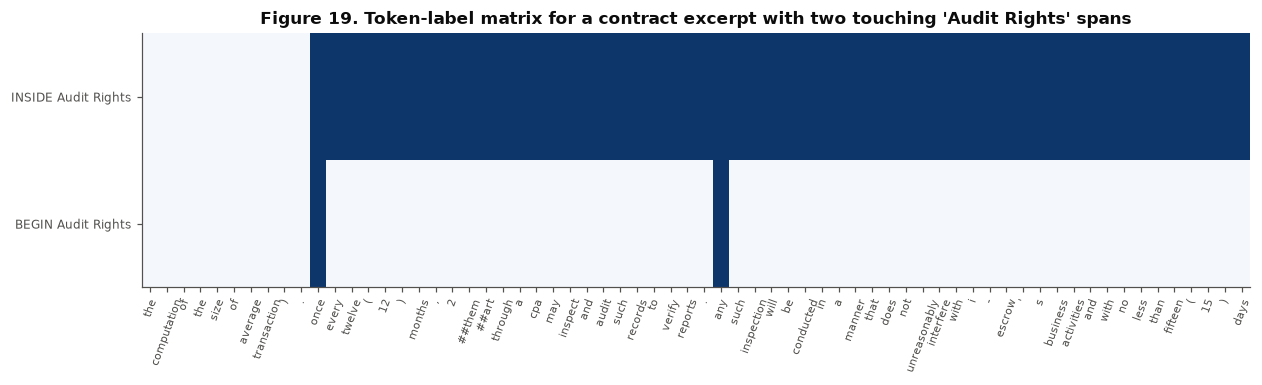

In [5]:
d = spans.drop_duplicates(["contract", "category", "start", "end"]).sort_values(["contract", "category", "start"])
d["prev_end"] = d.groupby(["contract", "category"]).end.shift()
nb = d.dropna(subset=["prev_end"])
touch = (nb.start - nb.prev_end) <= 1
print(f"Neighbouring same-category span pairs: {len(nb):,}; touching or overlapping (gap <= 1 character): {touch.sum():,} "
      f"({100 * touch.mean():.1f} %)")

LABELS = {c: D.token_labels(corpus[c]["offsets"], [(CIDX[r.category], r.start, r.end) for r in spans[spans.contract == c].itertuples()], K)
          for c in cs.contract}
pos_share = np.concatenate([LABELS[c] for c in SPLIT["train"]])[:, :K].mean()
print(f"Share of (token, category) INSIDE targets that are positive in train: {100 * pos_share:.2f} % -> heavy imbalance")

# A real example with two touching spans of one category: text and token-label matrix
ex = nb[touch].iloc[0]
c0, cat0 = ex.contract, ex.category
s0, e0 = int(ex.prev_end) - 160, int(ex.start) + 160
offs = corpus[c0]["offsets"]; tsel = np.flatnonzero((offs[:, 1] > s0) & (offs[:, 0] < e0))
toks = tok.convert_ids_to_tokens([corpus[c0]["ids"][i] for i in tsel])
used = [k for k in range(K) if LABELS[c0][tsel, k].any()]
print(f"\nContract: {c0[:70]}\nCategory with two touching spans: {cat0}\nExcerpt: {TEXT[c0][s0:e0]!r}")
mat = np.vstack([LABELS[c0][tsel][:, used].T, LABELS[c0][tsel][:, [K + k for k in used]].T])
fig, ax = plt.subplots(figsize=(13, 0.5 * len(mat) + 2))
ax.imshow(mat, aspect="auto", cmap=PL.BLUES, vmin=0, vmax=1)
ax.set_yticks(range(len(mat))); ax.set_yticklabels([f"INSIDE {CATS[k]}" for k in used] + [f"BEGIN {CATS[k]}" for k in used], fontsize=8)
step = max(1, len(toks) // 40)
ax.set_xticks(range(0, len(toks), step)); ax.set_xticklabels(toks[::step], rotation=70, fontsize=7); ax.grid(False)
ax.set_title(f"Figure 19. Token-label matrix for a contract excerpt with two touching '{cat0}' spans", fontsize=11)
PL.savefig(fig, 19, "t2_label_matrix"); plt.show()

**Interpretation.** 910 of the 4,670 neighbouring same-category span pairs (19.5 %) touch or overlap, which is why BEGIN
targets are needed (Figure 19 shows two touching *Audit Rights* spans: the INSIDE row is one continuous block, only the BEGIN
row shows where the second clause starts). Positive targets are very rare — 0.43 % of the (token, category) INSIDE targets in
training — so the model has to be trained against a strong pull towards "never inside".

### 2.4 Decoder: from per-token probabilities back to character spans
`D.decode` turns the model's per-token probabilities into spans, separately for each category: a span **starts** at a
token whose INSIDE probability is ≥ θ_inside when the previous token is outside, or when its BEGIN probability is ≥ θ_begin;
it **continues** while INSIDE ≥ θ_inside and **ends** before the next start. Its confidence is the mean INSIDE probability
of its tokens; spans shorter than `min_tokens` are dropped. The thresholds are tuned on validation (section 5). Probabilities
from overlapping windows are averaged per token before decoding (`D.average_window_probs`).

### 2.5 ORACLE CHECK: is the label format lossless enough? (before any training)
We feed the **gold** token labels (probability 1 for every positive target) through the decoder and score the resulting
spans against the gold spans with the evaluation code of section 3 — once with INSIDE + BEGIN and once with INSIDE only.
This is the ceiling of the formulation: a perfect tagger could not score higher. It also tests the evaluation code
(a perfect prediction must score close to 1).

In [6]:
SNAPS = {c: (lambda o: (lambda s, e: D.span_token_range(o, s, e)))(corpus[c]["offsets"]) for c in cs.contract}

def spans_df(rows):
    return pd.DataFrame(rows, columns=["contract", "category", "start", "end", "confidence"])

def decode_contracts(probs_of, contracts, ti=0.5, tb=0.5, mt=1, use_begin=True):
    rows = []
    for c in contracts:
        for k, s, e, conf in D.decode(probs_of(c), corpus[c]["offsets"], K, ti, tb, mt, use_begin):
            rows.append((c, CATS[k], s, e, conf))
    return spans_df(rows)

oracle = {}
for split in ["validation", "test"]:
    gold = spans[spans.split == split]
    for use_begin in [True, False]:
        pred = decode_contracts(lambda c: LABELS[c].astype(np.float32), SPLIT[split], use_begin=use_begin)
        for mode in ["iou", "exact"]:
            s = M.summarise(M.count_table(gold, pred, SPLIT[split], CATS, mode=mode, snaps=SNAPS), CATS)
            oracle[f"{split} | {'INSIDE+BEGIN' if use_begin else 'INSIDE only'} | {'IoU>=0.5' if mode == 'iou' else 'exact'}"] = \
                {"macro_f1": s["macro_f1"], "micro_f1": s["micro_f1"]}
oracle_tab = pd.DataFrame(oracle).T
json.dump(oracle, open(C.RESULTS_DIR / "task2_oracle.json", "w"), indent=2)
display(oracle_tab.round(4))

,macro_f1,micro_f1
validation | INSIDE+BEGIN | IoU>=0.5,0.9973,0.9976
validation | INSIDE+BEGIN | exact,0.9920,0.9918
validation | INSIDE only | IoU>=0.5,0.9200,0.9191
validation | INSIDE only | exact,0.8367,0.8417
test | INSIDE+BEGIN | IoU>=0.5,0.9976,0.9976
test | INSIDE+BEGIN | exact,0.9952,0.9935
test | INSIDE only | IoU>=0.5,0.9317,0.9164
test | INSIDE only | exact,0.8703,0.8461


**Interpretation (`results/task2_oracle.json`).** With INSIDE + BEGIN, decoding the gold labels gives macro-F1 **0.998** at IoU 0.5
on test (0.995 at exact token boundaries): the formulation and the evaluation code are essentially lossless (the small loss
comes from rare cases such as two spans of one category sharing a token). With INSIDE only, the ceiling falls to **0.932**
(0.870 exact), because touching clauses are merged into one span. So BEGIN markers raise the achievable score by about 0.07,
before any model is trained.

## 3. Evaluation code (`src/span_metrics.py`)
**Our entity-level metrics (primary).** For each (contract, category), predicted spans are matched **one-to-one** to gold
spans, greedily in order of confidence. A pair matches at **IoU ≥ 0.5** (character-level Jaccard of the two ranges, CUAD's
threshold) or, for the strict variant, when both cover **exactly the same word-pieces**. Unmatched predictions are false
positives — also in contracts that have no span of that category — and unmatched gold spans are false negatives. We report
precision, recall and F1 per category, micro (pooled counts) and **macro over the 27 categories (primary: macro-F1 at IoU
0.5)**, plus token-level F1 on the INSIDE targets.

**CUAD-style metrics** replicate the official `evaluate.py` (read from https://github.com/TheAtticusProject/cuad): word-set
Jaccard ≥ 0.5 on the span *texts* (punctuation `. , ; :` removed, lower-cased); a gold span is a TP if *any* prediction matches
it (not one-to-one); a prediction matching no gold span is an FP; counts pooled over all (contract, category) pairs; the
confidence threshold is swept from 0.99 to 0; precision is made monotone; **AUPR** is the area under that curve and
**precision at 80 % / 90 % recall** is read from it.

**Differences from CUAD's evaluation, stated explicitly:** (1) our primary metric is one-to-one entity F1 at a tuned threshold,
CUAD reports AUPR over a threshold sweep; (2) our IoU is character-based, CUAD's Jaccard is word-set based (we compute both);
(3) CUAD evaluates 41 categories, we evaluate 27; (4) CUAD's confidence is a QA answer probability, ours is the mean INSIDE
probability of a decoded span.

**Uncertainty:** contract-level bootstrap (1,000 resamples of whole contracts); in each resample macro-F1 is averaged over
the categories with at least one gold span in that resample (the same rule as in Task 1).

The unit tests below check the metrics and the decoder on tiny hand-made examples.

In [7]:
sys.path.insert(0, str(ROOT / "tests"))
import test_task2
importlib.reload(test_task2)
for name in [n for n in dir(test_task2) if n.startswith("test_")]:
    getattr(test_task2, name)()
    print("passed:", name)

passed: test_counts_summary_and_cuad
passed: test_iou_and_match
passed: test_labels_and_decoder_roundtrip
passed: test_windows_and_averaging


## 4. Baseline: TF-IDF segment classifier (`t2_tfidf_segments`)
Each contract is cut into **segments** with a documented rule (`src/task2_baseline.py`: line breaks; sentence or item ends
followed by a new sentence; inline enumerations such as "(a) "). A segment is labelled positive for a category if at least
50 % of its characters lie inside a gold span of that category (multi-label). One TF-IDF (word 1–2-grams, sublinear tf,
min_df 2) feeds 27 binary Logistic Regressions, one per category. Positive segments that are neighbours are merged into
one span (confidence = mean probability). Hyper-parameters (C, class weights, decision threshold) were searched on
**validation** (`scripts/t2_baseline_search.py`, all settings in `results/task2_baseline_search.csv`).

Its **oracle ceiling** — perfect segment classification, merged the same way — shows how much the segmentation itself costs.

In [8]:
SEGS = {c: B.segment(TEXT[c]) for c in cs.contract}
seg_len = pd.Series([e - s for c in SEGS for s, e in SEGS[c]])
print({s: f"{sum(len(SEGS[c]) for c in SPLIT[s]):,} segments" for s in SPLIT},
      f"| segment length median {seg_len.median():.0f} chars, 95th percentile {seg_len.quantile(.95):.0f}")
SEG_Y = {c: B.segment_labels(SEGS[c], [(CIDX[r.category], r.start, r.end) for r in spans[spans.contract == c].itertuples()], K)
         for c in cs.contract}
seg_oracle = {}
for split in ["validation", "test"]:
    rows = [(c, CATS[k], s, e, conf) for c in SPLIT[split]
            for k, s, e, conf in B.merge_segments(SEGS[c], SEG_Y[c], SEG_Y[c].astype(float))]
    sm = M.summarise(M.count_table(spans[spans.split == split], spans_df(rows), SPLIT[split], CATS), CATS)
    seg_oracle[split] = {"macro_f1": sm["macro_f1"], "micro_f1": sm["micro_f1"]}
json.dump(seg_oracle, open(C.RESULTS_DIR / "task2_segment_oracle.json", "w"), indent=2)
print("Segmentation ORACLE ceiling (macro-F1 / micro-F1 at IoU 0.5):",
      {k: (round(v["macro_f1"], 4), round(v["micro_f1"], 4)) for k, v in seg_oracle.items()})

{'train': '128,026 segments', 'validation': '27,011 segments', 'test': '33,451 segments'} | segment length median 95 chars, 95th percentile 418


Segmentation ORACLE ceiling (macro-F1 / micro-F1 at IoU 0.5): {'validation': (0.8529, np.float64(0.8626)), 'test': (0.8589, np.float64(0.8446))}


108 settings searched on validation; selected: C = 30, class_weight = None, threshold = 0.2 (validation macro-F1 0.4317)


,C,class_weight,threshold,val_macro_f1,val_micro_f1,val_macro_precision,val_macro_recall,fit_seconds
73,30.0,None,0.2,0.4317,0.5060,0.5082,0.3975,8.6958
91,100.0,None,0.2,0.4313,0.5031,0.5068,0.3960,10.4623
55,10.0,None,0.2,0.4300,0.5000,0.5024,0.3997,7.3534
92,100.0,None,0.3,0.4252,0.5093,0.5489,0.3667,10.4623
74,30.0,None,0.3,0.4246,0.5144,0.5549,0.3658,8.6958
56,10.0,None,0.3,0.4225,0.5133,0.5702,0.3600,7.3534
75,30.0,None,0.4,0.4156,0.5190,0.6026,0.3413,8.6958
93,100.0,None,0.4,0.4100,0.5085,0.5596,0.3429,10.4623
57,10.0,None,0.4,0.4076,0.5090,0.6290,0.3297,7.3534
54,10.0,None,0.1,0.4071,0.4522,0.3919,0.4534,7.3534


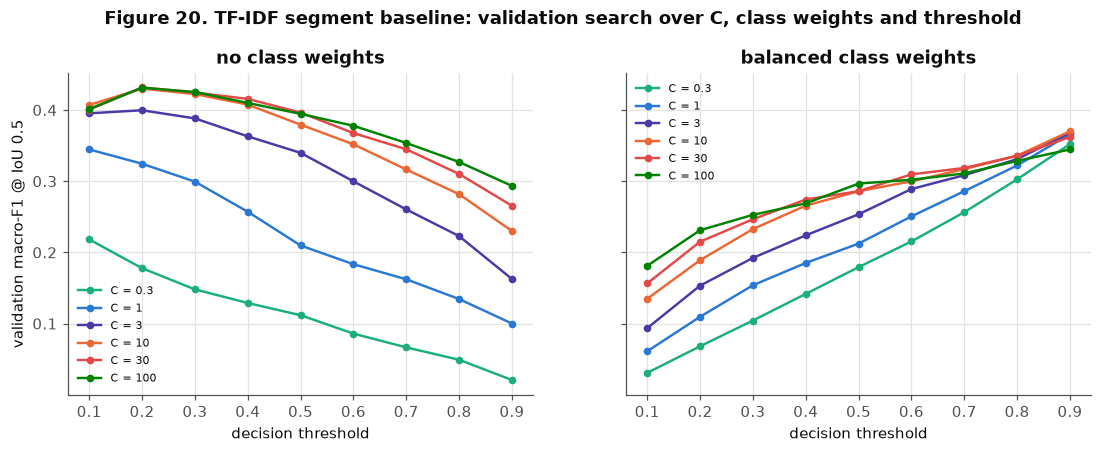

In [9]:
RUN_SEARCH = False      # True re-runs scripts/t2_baseline_search.py (about 2 min on the CPU)
if RUN_SEARCH:
    subprocess.run([sys.executable, "scripts/t2_baseline_search.py"], check=True)
bsearch = pd.read_csv(C.RESULTS_DIR / "task2_baseline_search.csv", keep_default_na=False)
bchoice = json.load(open(C.RESULTS_DIR / "task2_baseline_choice.json"))
print(f"{len(bsearch)} settings searched on validation; selected: C = {bchoice['C']:g}, class_weight = {bchoice['class_weight']}, "
      f"threshold = {bchoice['threshold']} (validation macro-F1 {bchoice['val_macro_f1']:.4f})")
display(bsearch.sort_values("val_macro_f1", ascending=False).head(10).round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, w in zip(axes, ["None", "balanced"]):
    g = bsearch[bsearch.class_weight == w]
    for k, (Cval, gg) in enumerate(g.groupby("C")):
        ax.plot(gg.threshold, gg.val_macro_f1, "o-", markersize=4, linewidth=1.6,
                color=[PL.AQUA, PL.BLUE, PL.VIOLET, PL.ORANGE, PL.RED, PL.GREEN][k], label=f"C = {Cval:g}")
    ax.set_title("no class weights" if w == "None" else "balanced class weights"); ax.set_xlabel("decision threshold")
    ax.legend(fontsize=7.5)
axes[0].set_ylabel("validation macro-F1 @ IoU 0.5")
fig.suptitle("Figure 20. TF-IDF segment baseline: validation search over C, class weights and threshold", fontweight="bold", y=1.03)
PL.savefig(fig, 20, "t2_baseline_search"); plt.show()

In [10]:
# Refit the selected baseline on the TRAIN segments; check that it reproduces the validation score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from joblib import Parallel, delayed

def seg_matrix(contracts):
    texts, index = [], []
    for c in contracts:
        texts += [TEXT[c][s:e] for s, e in SEGS[c]]; index += [(c, s, e) for s, e in SEGS[c]]
    return texts, index

tf_cfg = {**bchoice["tfidf"], "ngram_range": tuple(bchoice["tfidf"]["ngram_range"])}
tr_text, _ = seg_matrix(SPLIT["train"])
Ytr = np.vstack([SEG_Y[c] for c in SPLIT["train"]])
with C.timer("t2_tfidf_segments", "train_final", notes="TF-IDF + 27 one-vs-rest LogReg, selected config, train segments"):
    bvec = TfidfVectorizer(**tf_cfg).fit(tr_text)
    Xtr = bvec.transform(tr_text)
    bmodels = Parallel(n_jobs=14)(delayed(lambda k: LogisticRegression(C=bchoice["C"], class_weight=bchoice["class_weight"],
                                                                       solver="liblinear", max_iter=2000).fit(Xtr, Ytr[:, k]))(k)
                                  for k in range(K))

def baseline_predict(contracts, threshold):
    texts, index = seg_matrix(contracts)
    X = bvec.transform(texts)   # vectorise once, then score with each of the 27 one-vs-rest models
    P = np.column_stack([m.predict_proba(X)[:, 1] for m in bmodels])
    rows, pos = [], 0
    for c in contracts:
        n = len(SEGS[c]); p = P[pos:pos + n]; pos += n
        rows += [(c, CATS[k], s, e, conf) for k, s, e, conf in B.merge_segments(SEGS[c], p >= threshold, p)]
    return spans_df(rows), P

bval_pred, _ = baseline_predict(SPLIT["validation"], bchoice["threshold"])
bval = M.summarise(M.count_table(spans[spans.split == "validation"], bval_pred, SPLIT["validation"], CATS), CATS)
print(f"Baseline validation macro-F1 @ IoU 0.5 after refit: {bval['macro_f1']:.4f} (search: {bchoice['val_macro_f1']:.4f})")
assert abs(bval["macro_f1"] - bchoice["val_macro_f1"]) < 1e-9

[timer] t2_tfidf_segments / train_final: 14.4 s


Baseline validation macro-F1 @ IoU 0.5 after refit: 0.4317 (search: 0.4317)


**Interpretation (`results/task2_baseline_search.csv`, `results/task2_segment_oracle.json`).** The heuristic segmentation alone
caps the baseline at macro-F1 **0.859** on test even with a perfect classifier: neighbouring clauses of one category are merged
into one span and segment edges do not always coincide with clause edges. The search over 108 settings (C up to 100, thresholds
0.1–0.9; the first, narrower grid had its optimum on the edge and was extended) selected C = 30 without class weights and a
**low decision threshold of 0.2** (validation macro-F1 0.432; C = 10–100 within 0.002). A low threshold is needed because each
category's segments are rare, so the classifiers' probabilities for positive segments are small; balanced class weights raise
recall but produce too many false positives (best 0.32).

## 5. Main model: Legal-BERT token tagger (`t2_legalbert_tagger`)
**Model.** The *base* checkpoint `nlpaueb/legal-bert-base-uncased` (not the Task 1 fine-tuned model, which is reused in
Part F) with a token-classification head of **54 sigmoid outputs** (INSIDE + BEGIN × 27 categories), trained with our own
multi-label binary cross-entropy on 256-token windows (stride 128; section 2.2), masked on [CLS]/[SEP]/padding.
Recipe: AdamW (lr 5e-5, weight decay 0.01), 10 % warm-up and linear decay, batch 16, 4 epochs, bf16, gradient clipping 1.0.

**Imbalance.** Positive targets are rare (section 2.3). Two levers: (1) **negative-window sampling** — every window
containing a gold span plus a random 20 % of the span-free windows, re-sampled every epoch; (2) the **loss**, chosen among
three documented variants **on validation**: plain BCE; BCE with a per-output positive weight
`clip(sqrt(#negatives / #positives), 1, 30)`; and focal loss (γ = 2), which down-weights easy tokens.

**Rules fixed before training** (`scripts/train_task2.py`): each variant is trained with seed 42; the epoch and the variant
are chosen by validation macro-F1 at IoU 0.5 decoded with default thresholds (0.5 / 0.5 / 1 token); the chosen variant is
repeated with seeds 43 and 44 (validation mean ± std); the **test model is seed 42** of the chosen variant.

In [11]:
RETRAIN = False     # True runs: python scripts/train_task2.py --plan  (about 25 min on an RTX 5080)
if RETRAIN:
    subprocess.run([sys.executable, "scripts/train_task2.py", "--plan"], check=True)
b256 = bench["256/128"]
print(f"Benchmark (window 256 / stride 128): {b256['ms_per_step_batch16']:.0f} ms per step, {b256['windows_per_epoch']:,} windows "
      f"per epoch -> {b256['projected_epoch_minutes']:.1f} min per epoch; whole plan projected "
      f"{bench['projection_256_128']['projected_training_hours'] * 60:.0f} min (training steps only) -> no cuts needed.")
tsearch = pd.read_csv(C.RESULTS_DIR / "task2_search.csv")
tlog = pd.read_csv(C.RESULTS_DIR / "task2_log.csv")
tchoice = json.load(open(C.RESULTS_DIR / "task2_choice.json"))
display(tsearch[["run_id", "variant", "seed", "best_epoch", "val_macro_f1", "val_micro_f1", "steps_per_epoch",
                 "mean_epoch_train_seconds", "run_seconds", "peak_gpu_mem_gb"]].round(4))
print("Chosen:", tchoice)

Benchmark (window 256 / stride 128): 53 ms per step, 12,656 windows per epoch -> 0.7 min per epoch; whole plan projected 14 min (training steps only) -> no cuts needed.


,run_id,variant,seed,best_epoch,val_macro_f1,val_micro_f1,steps_per_epoch,mean_epoch_train_seconds,run_seconds,peak_gpu_mem_gb
0,t2_bce_plain_s42,bce_plain,42,4,0.4576,0.4943,791,47.0778,224.6545,3.2414
1,t2_bce_posw_s42,bce_posw,42,4,0.2792,0.2921,791,46.5236,220.6733,3.2374
2,t2_focal_s42,focal,42,4,0.3972,0.4134,791,46.2396,224.4608,3.2388
3,t2_bce_plain_s43,bce_plain,43,4,0.4282,0.4664,791,45.9588,208.6772,3.2653
4,t2_bce_plain_s44,bce_plain,44,4,0.4344,0.4922,791,45.9842,208.7019,3.2692
5,t2_bce_plain_s42_e8,bce_plain,42,6,0.4825,0.5100,791,46.0875,431.7886,3.2665
6,t2_bce_plain_s43_e8,bce_plain,43,8,0.4930,0.5202,791,45.9689,417.4448,3.2655
7,t2_bce_plain_s44_e8,bce_plain,44,7,0.4908,0.5133,791,45.9315,417.1056,3.2661


Chosen: {'variant': 'bce_plain', 'test_run': 't2_bce_plain_s42_e8', 'val_macro_f1_seed42': 0.4825232860044291, 'val_macro_f1_mean': 0.4887730106711505, 'val_macro_f1_std': 0.005521278475255023, 'n_seeds': 3, 'epoch_extension': {'triggered': True, 'epochs': 8, 'val_macro_f1_4_epochs': 0.457632620461725, 'val_macro_f1_extended': 0.4825232860044291, 'adopted': True}, 'epochs': 8}


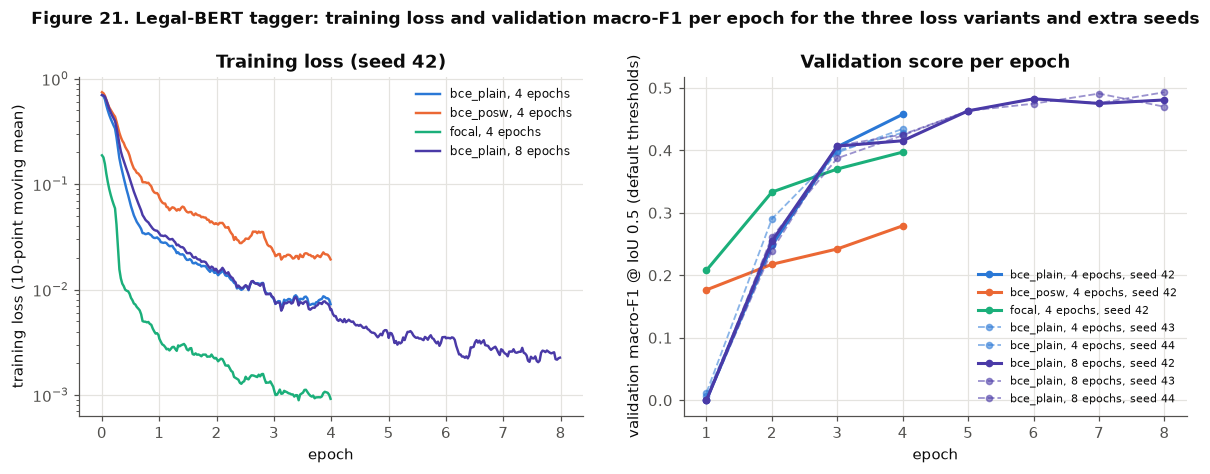

,run_id,epoch,train_loss,val_macro_f1,val_macro_precision,val_macro_recall,epoch_train_seconds,val_predict_seconds
40,t2_bce_plain_s42,1,0.1180,0.0006,0.0014,0.0004,47.2338,5.1523
81,t2_bce_plain_s42,2,0.0191,0.2478,0.2421,0.2909,47.0606,5.2169
122,t2_bce_plain_s42,3,0.0108,0.4057,0.3753,0.4645,46.9616,5.1960
163,t2_bce_plain_s42,4,0.0077,0.4576,0.5053,0.4774,47.0551,5.1803
204,t2_bce_posw_s42,1,0.2019,0.1767,0.1141,0.4994,47.0751,5.1952
245,t2_bce_posw_s42,2,0.0516,0.2176,0.1489,0.5575,46.7156,5.0689
286,t2_bce_posw_s42,3,0.0310,0.2422,0.1591,0.5882,46.2020,5.0831
327,t2_bce_posw_s42,4,0.0205,0.2792,0.1858,0.6515,46.1017,5.1454
368,t2_focal_s42,1,0.0192,0.2080,0.1746,0.2962,46.2775,5.0668
409,t2_focal_s42,2,0.0025,0.3332,0.2647,0.5118,46.1955,5.0941


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
vcol = {"bce_plain": PL.BLUE, "bce_posw": PL.ORANGE, "focal": PL.AQUA}
ts = tsearch.set_index("run_id")
for rid in tsearch.run_id:
    var, seed, n_ep = ts.loc[rid, "variant"], ts.loc[rid, "seed"], int(ts.loc[rid, "epochs"])
    st = tlog[(tlog.run_id == rid) & (tlog.kind == "step")]; ep = tlog[(tlog.run_id == rid) & (tlog.kind == "epoch")]
    spe = ts.loc[rid, "steps_per_epoch"]
    col = PL.VIOLET if n_ep == 8 else vcol[var]
    ls = "-" if seed == 42 else "--"
    if seed == 42:
        axes[0].plot(st.step / spe, st.train_loss.rolling(10, min_periods=1).mean(), ls, color=col, linewidth=1.6,
                     label=f"{var}, {n_ep} epochs")
    axes[1].plot(ep.epoch, ep.val_macro_f1, ls, marker="o", markersize=4, color=col, linewidth=2 if seed == 42 else 1.2,
                 alpha=1 if seed == 42 else 0.55, label=f"{var}, {n_ep} epochs, seed {seed}")
axes[0].set_yscale("log"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("training loss (10-point moving mean)")
axes[0].set_title("Training loss (seed 42)"); axes[0].legend(fontsize=8)
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("validation macro-F1 @ IoU 0.5 (default thresholds)")
axes[1].set_title("Validation score per epoch"); axes[1].legend(fontsize=7.5)
fig.suptitle("Figure 21. Legal-BERT tagger: training loss and validation macro-F1 per epoch for the three loss variants and extra seeds",
             fontweight="bold", y=1.03, fontsize=11)
PL.savefig(fig, 21, "t2_tagger_curves"); plt.show()
display(tlog[tlog.kind == "epoch"][["run_id", "epoch", "train_loss", "val_macro_f1", "val_macro_precision", "val_macro_recall",
                                    "epoch_train_seconds", "val_predict_seconds"]].round(4))

**Interpretation (Figure 21, `results/task2_search.csv`).**
* **Variant choice (pre-declared rule):** plain BCE (validation macro-F1 0.458 after 4 epochs) beat focal loss (0.397) and
  positive-weighted BCE (0.279). Positive weighting makes the model predict "inside" far too often (macro recall 0.65 but precision
  0.19), which the span metric punishes; focal loss learns faster in epoch 1 but levels off lower. Negative-window sampling alone
  already handles the imbalance well enough for plain BCE.
* **Epochs:** plain BCE was still improving at epoch 4, so the rule recorded before the other variants were seen
  retrained it for 8 epochs: seed 42 rose to **0.483** (best epoch 6), and 8 epochs were adopted. With seeds 43 and 44 the 8-epoch
  recipe scores **0.489 ± 0.006** on validation (4 epochs: 0.440 ± 0.016).
* **Curves:** the score is near zero after epoch 1 (the model first learns that almost everything is outside), jumps in epochs 2–3,
  and flattens from epoch 6 while the training loss keeps falling — further epochs would mostly fit the training contracts.
* One run takes about 7 minutes for 8 epochs (46 s per epoch plus 5 s for decoding the validation contracts; peak 3.3 GB).

### 5.1 Decoding thresholds (validation only)
The saved validation probabilities of the test run are decoded with a grid of thresholds: θ_inside ∈ {0.2, …, 0.8},
θ_begin ∈ {0.3, 0.5, 0.7} and `min_tokens` ∈ {1, 3, 5, 10}; the setting with the highest validation macro-F1 at IoU 0.5 is
used on test (one global setting). **Per-category thresholds** could adapt to each category but can easily over-fit the
small number of validation spans per category; we only adopt them if they help on validation contracts that were *not* used
to tune them (split-half check: tune on one half of the validation contracts, score on the other half, both ways round).

Selected global thresholds: {'theta_inside': 0.6, 'theta_begin': 0.3, 'min_tokens': 10} -> validation macro-F1 0.5652 (defaults 0.5/0.5/1: 0.4825)


,theta_inside,theta_begin,min_tokens,val_macro_f1,val_micro_f1,val_macro_precision,val_macro_recall
55,0.6,0.5,10,0.5652,0.6055,0.6369,0.5272
59,0.6,0.7,10,0.5652,0.6055,0.6369,0.5272
51,0.6,0.3,10,0.5652,0.6055,0.6369,0.5272
43,0.5,0.5,10,0.5630,0.5954,0.6100,0.5436
47,0.5,0.7,10,0.5630,0.5954,0.6100,0.5436
39,0.5,0.3,10,0.5630,0.5954,0.6100,0.5436
58,0.6,0.7,5,0.5521,0.5923,0.6068,0.5272
50,0.6,0.3,5,0.5521,0.5923,0.6068,0.5272


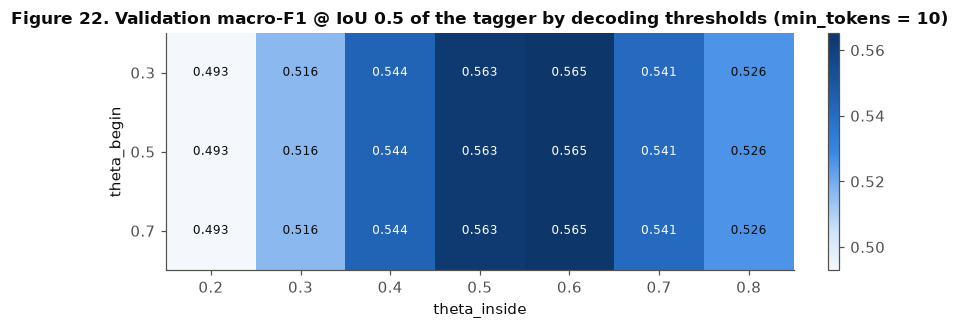

In [13]:
%%needs_models models/task2
TEST_RUN = tchoice["test_run"]
RUN_DIR = ROOT / "models" / "task2" / TEST_RUN
vz = np.load(RUN_DIR / "val_probs.npz")
VPROBS = {c: vz[f"c{i}"].astype(np.float32) for i, c in enumerate(SPLIT["validation"])}
gold_val = spans[spans.split == "validation"]
grid = []
for ti in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    for tb in [0.3, 0.5, 0.7]:
        for mt in [1, 3, 5, 10]:
            pv = decode_contracts(VPROBS.get, SPLIT["validation"], ti, tb, mt)
            sm = M.summarise(M.count_table(gold_val, pv, SPLIT["validation"], CATS), CATS)
            grid.append({"theta_inside": ti, "theta_begin": tb, "min_tokens": mt, "val_macro_f1": sm["macro_f1"],
                         "val_micro_f1": sm["micro_f1"], "val_macro_precision": sm["macro_precision"], "val_macro_recall": sm["macro_recall"]})
grid = pd.DataFrame(grid); grid.to_csv(C.RESULTS_DIR / "task2_threshold_search.csv", index=False)
best_t = grid.sort_values(["val_macro_f1", "min_tokens"], ascending=[False, True]).iloc[0]
TH = {"theta_inside": float(best_t.theta_inside), "theta_begin": float(best_t.theta_begin), "min_tokens": int(best_t.min_tokens)}
default = grid[(grid.theta_inside == 0.5) & (grid.theta_begin == 0.5) & (grid.min_tokens == 1)].val_macro_f1.iloc[0]
print(f"Selected global thresholds: {TH} -> validation macro-F1 {best_t.val_macro_f1:.4f} (defaults 0.5/0.5/1: {default:.4f})")
display(grid.sort_values("val_macro_f1", ascending=False).head(8).round(4))

pivot = grid[grid.min_tokens == TH["min_tokens"]].pivot_table(index="theta_begin", columns="theta_inside", values="val_macro_f1")
fig, ax = plt.subplots(figsize=(8, 2.8))
im = ax.imshow(pivot.values, cmap=PL.BLUES, aspect="auto")
ax.set_xticks(range(pivot.shape[1])); ax.set_xticklabels(pivot.columns); ax.set_yticks(range(pivot.shape[0])); ax.set_yticklabels(pivot.index)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        ax.text(j, i, f"{pivot.values[i, j]:.3f}", ha="center", va="center", fontsize=8,
                color="white" if pivot.values[i, j] > pivot.values.mean() else PL.INK)
ax.set_xlabel("theta_inside"); ax.set_ylabel("theta_begin"); ax.grid(False); fig.colorbar(im, ax=ax, fraction=0.03)
ax.set_title(f"Figure 22. Validation macro-F1 @ IoU 0.5 of the tagger by decoding thresholds (min_tokens = {TH['min_tokens']})", fontsize=11)
PL.savefig(fig, 22, "t2_threshold_grid"); plt.show()

In [14]:
%%needs_models models/task2
# Split-half check for per-category inside thresholds (validation only)
rng = np.random.default_rng(42)
vc = np.array(SPLIT["validation"]); perm = rng.permutation(len(vc)); halves = [list(vc[perm[:len(vc) // 2]]), list(vc[perm[len(vc) // 2:]])]
def per_cat_f1(contracts, ti_map):
    rows = []
    for c in contracts:
        for k in range(K):
            p = VPROBS[c]
            for _, s, e, conf in D.decode(np.c_[p[:, [k]], p[:, [K + k]]], corpus[c]["offsets"], 1, ti_map[k], TH["theta_begin"], TH["min_tokens"]):
                rows.append((c, CATS[k], s, e, conf))
    return M.summarise(M.count_table(gold_val[gold_val.contract.isin(contracts)], spans_df(rows), contracts, CATS), CATS)
def single_cat_f1(contracts, k, t):
    rows = [(c, CATS[k], s, e, conf) for c in contracts
            for _, s, e, conf in D.decode(np.c_[VPROBS[c][:, [k]], VPROBS[c][:, [K + k]]], corpus[c]["offsets"], 1, t,
                                          TH["theta_begin"], TH["min_tokens"])]
    cnt = M.count_table(gold_val[gold_val.contract.isin(contracts) & (gold_val.category == CATS[k])], spans_df(rows), contracts, [CATS[k]])
    return M.prf(cnt.tp.sum(), cnt.fp.sum(), cnt.fn.sum())[2]
check = []
for a, b in [(0, 1), (1, 0)]:
    tuned = {}
    for k in range(K):
        n_spans = (gold_val[gold_val.contract.isin(halves[a])].category == CATS[k]).sum()
        if n_spans < 10:
            tuned[k] = TH["theta_inside"]; continue
        best_k = max([0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8], key=lambda t: single_cat_f1(halves[a], k, t))
        tuned[k] = best_k
    glob = per_cat_f1(halves[b], {j: TH["theta_inside"] for j in range(K)})["macro_f1"]
    perc = per_cat_f1(halves[b], tuned)["macro_f1"]
    n_tuned = int(sum((gold_val[gold_val.contract.isin(halves[a])].category == CATS[k]).sum() >= 10 for k in range(K)))
    check.append({"tuned on half": a, "scored on half": b, "global macro-F1": glob, "per-category macro-F1": perc,
                  "categories with >= 10 spans (tuned)": n_tuned})
check = pd.DataFrame(check); display(check.round(4))
USE_PER_CAT = bool((check["per-category macro-F1"] > check["global macro-F1"]).all())
json.dump({**TH, "per_category_split_half": check.to_dict(orient="records"), "use_per_category": USE_PER_CAT},
          open(C.RESULTS_DIR / "task2_thresholds.json", "w"), indent=2, default=float)
print("Per-category thresholds adopted:", USE_PER_CAT, "(only if they help on the held-out half in BOTH directions)")

,tuned on half,scored on half,global macro-F1,per-category macro-F1,categories with >= 10 spans (tuned)
0,0,1,0.6084,0.5720,22
1,1,0,0.5064,0.5273,23


Per-category thresholds adopted: False (only if they help on the held-out half in BOTH directions)


**Interpretation (`results/task2_threshold_search.csv`, Figure 22, `results/task2_thresholds.json`).** Tuning the decoder on
validation raises macro-F1 from 0.483 (defaults) to **0.565**: θ_inside = 0.6 and **min_tokens = 10** — dropping very short
fragments removes many spurious pieces — while θ_begin makes no difference (0.3, 0.5 and 0.7 give identical scores, because the
BEGIN probabilities are almost always either close to 0 or close to 1; 0.3 was kept by the tie-break order). **Per-category
thresholds were not adopted:** in the split-half check they helped in one direction (0.506 → 0.527) but hurt in the other
(0.608 → 0.572), the typical sign of over-fitting a handful of validation spans per category.

### 5.2 Window-size sensitivity (validation only)
The test model uses 256-token windows with stride 128, as fixed in the design. A longer window sees more context and
fits more gold spans completely (section 2.2), so one extra tagger was trained with **384/192 windows** — same recipe,
loss, 8 epochs and seed 42 (`python scripts/train_task2.py --window384`, logged in
`results/task2_window_sensitivity_*.csv`). It is compared with the 256/128 model **on validation only**, at the default
thresholds and after re-tuning its own thresholds on the same grid as section 5.1. It is **never evaluated on test**;
the test model stays 256/128 whatever the result (decided before training it).

In [15]:
W384_RUN = "t2_bce_plain_s42_e8_w384"
w_search = pd.read_csv(C.RESULTS_DIR / "task2_window_sensitivity_search.csv")
wz_file = ROOT / "models" / "task2" / W384_RUN / "val_probs.npz"
wchoice = pd.read_csv(C.RESULTS_DIR / "task2_window_choice.csv").set_index("window/stride")
def tune_on_val(probs):
    best = None
    for ti in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
        for tb in [0.3, 0.5, 0.7]:
            for mt in [1, 3, 5, 10]:
                sm = M.summarise(M.count_table(gold_val, decode_contracts(probs.get, SPLIT["validation"], ti, tb, mt),
                                               SPLIT["validation"], CATS), CATS)
                if best is None or sm["macro_f1"] > best[0] + 1e-12:
                    best = (sm["macro_f1"], ti, tb, mt, sm["macro_precision"], sm["macro_recall"])
    return best
if wz_file.exists():
    wz = np.load(wz_file); W384_PROBS = {c: wz[f"c{i}"].astype(np.float32) for i, c in enumerate(SPLIT["validation"])}
    rows = []
    for label, probs, run in [("256/128 (test model)", VPROBS, TEST_RUN), ("384/192", W384_PROBS, W384_RUN)]:
        d = M.summarise(M.count_table(gold_val, decode_contracts(probs.get, SPLIT["validation"]), SPLIT["validation"], CATS), CATS)
        t = tune_on_val(probs)
        meta = (tsearch if run == TEST_RUN else w_search).set_index("run_id").loc[run]
        key = label.split(" ")[0]
        rows.append({"window/stride": label, "best epoch": int(meta.best_epoch),
                     "val macro-F1 (default thresholds)": d["macro_f1"],
                     "val macro-F1 (own tuned thresholds)": t[0], "tuned (theta_i, theta_b, min_tokens)": f"{t[1]}, {t[2]}, {t[3]}",
                     "macro P / R (tuned)": f"{t[4]:.3f} / {t[5]:.3f}",
                     "gold spans fully inside >= 1 window %": float(wchoice.loc[key, "spans fully inside >= 1 window %"]),
                     "training seconds": float(meta.run_seconds), "peak GPU GB": float(meta.peak_gpu_mem_gb)})
    wtab = pd.DataFrame(rows)
    wtab.to_csv(C.RESULTS_DIR / "task2_window_sensitivity.csv", index=False)
    display(wtab.round(4))
    gain = wtab.iloc[1]["val macro-F1 (own tuned thresholds)"] - wtab.iloc[0]["val macro-F1 (own tuned thresholds)"]
    print(f"384/192 minus 256/128 on validation (each with its own tuned thresholds): {gain:+.4f} macro-F1 @ IoU 0.5 "
          f"(one seed each; the seed-to-seed spread of the 256/128 recipe is std {tchoice['val_macro_f1_std']:.4f}). "
          "The test model stays 256/128.")
else:
    print("384/192 validation probabilities not found (models/ is not in the repository); the saved table is shown instead.")
    display(pd.read_csv(C.RESULTS_DIR / "task2_window_sensitivity.csv").round(4))

,window/stride,best epoch,val macro-F1 (default thresholds),val macro-F1 (own tuned thresholds),"tuned (theta_i, theta_b, min_tokens)",macro P / R (tuned),gold spans fully inside >= 1 window %,training seconds,peak GPU GB
0,256/128 (test model),6,0.4825,0.5652,"0.6, 0.3, 10",0.637 / 0.527,95.7196,431.7886,3.2665
1,384/192,8,0.4850,0.5451,"0.5, 0.3, 10",0.617 / 0.499,98.4142,459.0423,4.1047


384/192 minus 256/128 on validation (each with its own tuned thresholds): -0.0201 macro-F1 @ IoU 0.5 (one seed each; the seed-to-seed spread of the 256/128 recipe is std 0.0055). The test model stays 256/128.


**Interpretation (`results/task2_window_sensitivity.csv`; validation only).** Longer windows fit more gold spans completely
(98.4 % vs 95.7 % of spans inside at least one window) at slightly higher cost (460 vs 432 s of training, 4.1 vs 3.3 GB). At the
default thresholds the two window sizes are practically equal (0.485 vs 0.483 macro-F1 at IoU 0.5). After each model's own
threshold tuning the 384/192 model is **0.020 lower** (0.545 vs 0.565). That is a single seed each, and the 256/128 recipe alone
varies with std 0.006 across seeds, so the honest reading is "no evidence that longer windows help". The few extra spans that now
fit in one window are not where the errors are: only 11 of the tagger's 798 missed test spans are longer than a 256-token window
(section 8.1). The pre-declared 256/128 test model stays as it is; no test evaluation was made with 384/192.

## 6. Test evaluation (once per model)
Both models are now applied to the **102 official test contracts** with the settings fixed on validation and scored once
each through `C.test_once_spans`, which logs the evaluation in `results/test_eval_log.csv` and refuses a second one.

In [16]:
%%needs_models models/task2
gold_test = spans[spans.split == "test"]
# --- baseline ---
btest_pred, _ = baseline_predict(SPLIT["test"], bchoice["threshold"])
# --- tagger: per-token test probabilities (computed once with the saved weights, then cached in models/) ---
tp_file = RUN_DIR / "test_probs.npz"
if not tp_file.exists() and (RUN_DIR / "best").exists():
    subprocess.run([sys.executable, "scripts/train_task2.py", "--predict", TEST_RUN, "--split", "test"], check=True)
if tp_file.exists():
    tz = np.load(tp_file); TPROBS = {c: tz[f"c{i}"].astype(np.float32) for i, c in enumerate(SPLIT["test"])}
    ttest_pred = decode_contracts(TPROBS.get, SPLIT["test"], TH["theta_inside"], TH["theta_begin"], TH["min_tokens"])
else:
    print("Tagger weights and cached probabilities not found: loading the saved test spans instead.")
    TPROBS = None
    ttest_pred = pd.read_csv(C.RESULTS_DIR / "task2" / "t2_legalbert_tagger_test_spans.csv")

def full_metrics(pred, probs=None, seg_pos=None):
    out = {}
    cnt = M.count_table(gold_test, pred, SPLIT["test"], CATS)
    s = M.summarise(cnt, CATS); se = M.summarise(M.count_table(gold_test, pred, SPLIT["test"], CATS, mode="exact", snaps=SNAPS), CATS)
    out.update({k: s[k] for k in ["macro_f1", "micro_f1", "macro_precision", "macro_recall", "micro_precision", "micro_recall"]})
    out.update({"exact_macro_f1": se["macro_f1"], "exact_micro_f1": se["micro_f1"]})
    # token-level F1 on INSIDE targets
    pred_in = []
    for c in SPLIT["test"]:
        P = np.zeros((len(corpus[c]["offsets"]), K), dtype=bool)
        for r in pred[pred.contract == c].itertuples():
            rng_ = D.span_token_range(corpus[c]["offsets"], r.start, r.end)
            if rng_:
                P[rng_[0]:rng_[1] + 1, CIDX[r.category]] = True
        pred_in.append(P)
    out.update(M.token_f1(pred_in, [LABELS[c][:, :K] for c in SPLIT["test"]]))
    keys = [(c, k) for c in SPLIT["test"] for k in CATS]
    cur = M.cuad_curve(gold_test, pred, text_of, keys)
    out.update({"cuad_micro_aupr": cur["aupr"], "cuad_prec_at_80_recall": cur["prec_at_80_recall"],
                "cuad_prec_at_90_recall": cur["prec_at_90_recall"]})
    per_cat_aupr = {k: M.cuad_curve(gold_test[gold_test.category == k], pred[pred.category == k], text_of,
                                    [(c, k) for c in SPLIT["test"]])["aupr"] for k in CATS}
    out["cuad_macro_aupr"] = float(np.mean(list(per_cat_aupr.values())))
    free = pred[pred.contract.isin(SPAN_FREE_TEST)]
    out.update({"fp_in_span_free_contracts": int(len(free)), "span_free_contracts_with_any_prediction": int(free.contract.nunique())})
    return out, cnt, s, cur, per_cat_aupr

RES, CNT, SUMM, CURVE, PCAUPR = {}, {}, {}, {}, {}
for name, pred in [("t2_tfidf_segments", btest_pred), ("t2_legalbert_tagger", ttest_pred)]:
    RES[name], CNT[name], SUMM[name], CURVE[name], PCAUPR[name] = full_metrics(pred)
cfg_b = {**bchoice, "segmenter": "src/task2_baseline.py"}
cfg_t = {"run": TEST_RUN, "variant": tchoice["variant"], "thresholds": TH, "window": 256, "stride": 128, "base_checkpoint": CKPT}
C.test_once_spans("t2_tfidf_segments", cfg_b, RES["t2_tfidf_segments"], btest_pred)
C.test_once_spans("t2_legalbert_tagger", cfg_t, RES["t2_legalbert_tagger"], ttest_pred)

[test] t2_tfidf_segments: already evaluated once (see test_eval_log.csv); re-run reproduced the identical spans, saved metrics re-used.
[test] t2_legalbert_tagger: already evaluated once (see test_eval_log.csv); re-run reproduced the identical spans, saved metrics re-used.


{'macro_f1': 0.5229689008676477,
 'micro_f1': 0.5753335502766027,
 'macro_precision': 0.5988342363158331,
 'macro_recall': 0.49487886991303953,
 'micro_precision': 0.6355140186915887,
 'micro_recall': 0.525564803804994,
 'exact_macro_f1': 0.30028786480431335,
 'exact_micro_f1': 0.34689228766677516,
 'token_micro_f1': 0.6605394184629731,
 'token_macro_f1': 0.6250169503336116,
 'cuad_micro_aupr': 0.5241431121684029,
 'cuad_prec_at_80_recall': 0.0,
 'cuad_prec_at_90_recall': 0.0,
 'cuad_macro_aupr': 0.4926755121213809,
 'fp_in_span_free_contracts': 0,
 'span_free_contracts_with_any_prediction': 0}

In [17]:
%%needs_models models/task2
# Computational budget of the two Task 2 models -> results/compute_budget.csv (logged once)
t0 = time.perf_counter(); baseline_predict(SPLIT["test"], bchoice["threshold"]); b_inf = time.perf_counter() - t0
run = ts.loc[TEST_RUN]
tagger_inf = json.load(open(RUN_DIR / "test_predict_seconds.json")) if (RUN_DIR / "test_predict_seconds.json").exists() else None
budget = pd.read_csv(C.RESULTS_DIR / "compute_budget.csv")
new_rows = []
if not ((budget.model == "t2_legalbert_tagger") & (budget.stage == "train_final")).any():
    new_rows.append({"model": "t2_legalbert_tagger", "stage": "train_final", "seconds": round(float(run.run_seconds), 2),
                     "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
                     "notes": f"{int(run.epochs)} epochs x {int(run.steps_per_epoch)} steps (batch 16, window 256) incl. validation decoding; "
                              f"peak {run.peak_gpu_mem_gb:.1f} GB"})
    if tagger_inf:
        new_rows.append({"model": "t2_legalbert_tagger", "stage": "inference_test_gpu", "seconds": round(tagger_inf["seconds"], 2),
                         "device": torch.cuda.get_device_name(0), "notes": f"{tagger_inf['contracts']} test contracts, all windows, bf16"})
    new_rows.append({"model": "t2_tfidf_segments", "stage": "inference_test_cpu", "seconds": round(b_inf, 2), "device": "CPU",
                     "notes": f"{len(SPLIT['test'])} test contracts: segmentation + TF-IDF + 27 LogReg + merging"})
    budget = pd.concat([budget, pd.DataFrame([{**r, "timestamp": pd.Timestamp.now().isoformat(timespec="seconds")} for r in new_rows])],
                       ignore_index=True)
    budget.to_csv(C.RESULTS_DIR / "compute_budget.csv", index=False)
bt = budget[budget.model.isin(["t2_legalbert_tagger", "t2_tfidf_segments", "t2_tagger_plan"])]
display(bt[["model", "stage", "seconds", "device", "notes"]])
if tagger_inf:
    print(f"Tagger inference: {tagger_inf['seconds_per_contract']:.3f} s per contract on the GPU -> "
          f"{tagger_inf['seconds_per_contract'] * 1000 / 60:.1f} min per 1,000 contracts; "
          f"baseline: {b_inf / len(SPLIT['test']):.3f} s per contract on the CPU (this re-run)")

,model,stage,seconds,device,notes
10,t2_tfidf_segments,grid_search,64.76,"CPU (AMD64 Family 26 Model 68 Stepping 0, Auth...","first, narrower grid (C <= 10, thresholds 0.3-..."
11,t2_tfidf_segments,grid_search,128.88,"CPU (AMD64 Family 26 Model 68 Stepping 0, Auth...","extended grid: 108 settings (C <= 100, thresho..."
13,t2_tagger_plan,all_runs,1091.43,NVIDIA GeForce RTX 5080,3 loss variants + 2 extra seeds; validation only
14,t2_tagger_plan,epoch_extension,1269.05,NVIDIA GeForce RTX 5080,rule: chosen variant re-trained with 8 epochs ...
15,t2_tfidf_segments,train_final,14.18,"CPU (AMD64 Family 26 Model 68 Stepping 0, Auth...","TF-IDF + 27 one-vs-rest LogReg, selected confi..."
16,t2_tfidf_segments,train_final,14.46,"CPU (AMD64 Family 26 Model 68 Stepping 0, Auth...","TF-IDF + 27 one-vs-rest LogReg, selected confi..."
17,t2_legalbert_tagger,train_final,431.79,NVIDIA GeForce RTX 5080,"8 epochs x 791 steps (batch 16, window 256) in..."
18,t2_legalbert_tagger,inference_test_gpu,6.40,NVIDIA GeForce RTX 5080,"102 test contracts, all windows, bf16"
19,t2_tfidf_segments,inference_test_cpu,12.30,CPU,102 test contracts: segmentation + TF-IDF + 27...
31,t2_tfidf_segments,train_final,14.39,"CPU (AMD64 Family 26 Model 68 Stepping 0, Auth...","TF-IDF + 27 one-vs-rest LogReg, selected confi..."


Tagger inference: 0.063 s per contract on the GPU -> 1.0 min per 1,000 contracts; baseline: 0.123 s per contract on the CPU (this re-run)


In [18]:
%%needs_models models/task2
ci = {n: M.bootstrap_macro_f1(CNT[n], CATS) for n in CNT}
pb = M.paired_bootstrap_macro_f1(CNT["t2_legalbert_tagger"], CNT["t2_tfidf_segments"], CATS)
oracle_test = oracle["test | INSIDE+BEGIN | IoU>=0.5"]["macro_f1"]
rows = []
for label, n in [("TF-IDF segment baseline", "t2_tfidf_segments"), ("Legal-BERT tagger", "t2_legalbert_tagger")]:
    r = RES[n]
    rows.append({"model": label, "macro-F1 @ IoU0.5": r["macro_f1"], "95% CI": f"[{ci[n]['ci_low']:.3f}, {ci[n]['ci_high']:.3f}]",
                 "micro-F1 @ IoU0.5": r["micro_f1"], "macro P": r["macro_precision"], "macro R": r["macro_recall"],
                 "exact macro-F1": r["exact_macro_f1"], "token micro-F1": r["token_micro_f1"],
                 "CUAD-style AUPR (micro)": r["cuad_micro_aupr"], "P@80%R": r["cuad_prec_at_80_recall"], "P@90%R": r["cuad_prec_at_90_recall"],
                 "CUAD-style macro AUPR": r["cuad_macro_aupr"], "FP in 9 span-free contracts": r["fp_in_span_free_contracts"]})
rows.append({"model": "oracle ceilings (gold labels)", "macro-F1 @ IoU0.5": oracle_test,
             "95% CI": f"segments: {seg_oracle['test']['macro_f1']:.3f}"})
t2_table = pd.DataFrame(rows)
t2_table.to_csv(C.RESULTS_DIR / "task2_test_summary.csv", index=False)
display(t2_table.round(4))
print(f"Objective O4: tagger - baseline macro-F1 @ IoU0.5 = {pb['diff']:+.4f}, 95 % CI [{pb['ci_low']:+.4f}, {pb['ci_high']:+.4f}] -> "
      f"{'MET (CI above 0)' if pb['ci_low'] > 0 else 'NOT met'} for the first part of O4 (the CUAD comparison is in section 7)")
json.dump({"ci": ci, "paired_tagger_vs_baseline": pb, "oracle_test_macro_f1": oracle_test, "segment_oracle_test": seg_oracle["test"]},
          open(C.RESULTS_DIR / "task2_test_comparison.json", "w"), indent=2)

,model,macro-F1 @ IoU0.5,95% CI,micro-F1 @ IoU0.5,macro P,macro R,exact macro-F1,token micro-F1,CUAD-style AUPR (micro),P@80%R,P@90%R,CUAD-style macro AUPR,FP in 9 span-free contracts
0,TF-IDF segment baseline,0.3944,"[0.367, 0.431]",0.4678,0.4804,0.3657,0.2022,0.5582,0.4024,0.0,0.0,0.3433,0.0
1,Legal-BERT tagger,0.5230,"[0.490, 0.560]",0.5753,0.5988,0.4949,0.3003,0.6605,0.5241,0.0,0.0,0.4927,0.0
2,oracle ceilings (gold labels),0.9976,segments: 0.859,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Objective O4: tagger - baseline macro-F1 @ IoU0.5 = +0.1286, 95 % CI [+0.0990, +0.1551] -> MET (CI above 0) for the first part of O4 (the CUAD comparison is in section 7)


,gold test spans,train spans,baseline F1,tagger F1,tagger P,tagger R,tagger CUAD AUPR,tagger 95% CI
Competitive Restriction Exception,27.0,85,0.000,0.229,0.500,0.148,0.092,"[0.00, 0.44]"
Non-Disparagement,12.0,45,0.154,0.286,1.000,0.167,0.167,"[0.00, 0.67]"
Rofr/Rofo/Rofn,68.0,249,0.281,0.300,0.346,0.265,0.279,"[0.18, 0.41]"
Post-Termination Services,82.0,304,0.253,0.338,0.400,0.293,0.265,"[0.22, 0.46]"
Change Of Control,62.0,160,0.156,0.351,0.486,0.274,0.248,"[0.25, 0.47]"
Minimum Commitment,88.0,282,0.248,0.388,0.529,0.307,0.334,"[0.26, 0.53]"
Ip Ownership Assignment,61.0,212,0.489,0.391,0.581,0.295,0.307,"[0.25, 0.54]"
Source Code Escrow,5.0,50,0.000,0.400,0.400,0.400,0.400,"[0.40, 0.40]"
Volume Restriction,35.0,115,0.196,0.405,0.385,0.429,0.377,"[0.21, 0.56]"
Warranty Duration,19.0,133,0.375,0.412,0.467,0.368,0.374,"[0.19, 0.62]"


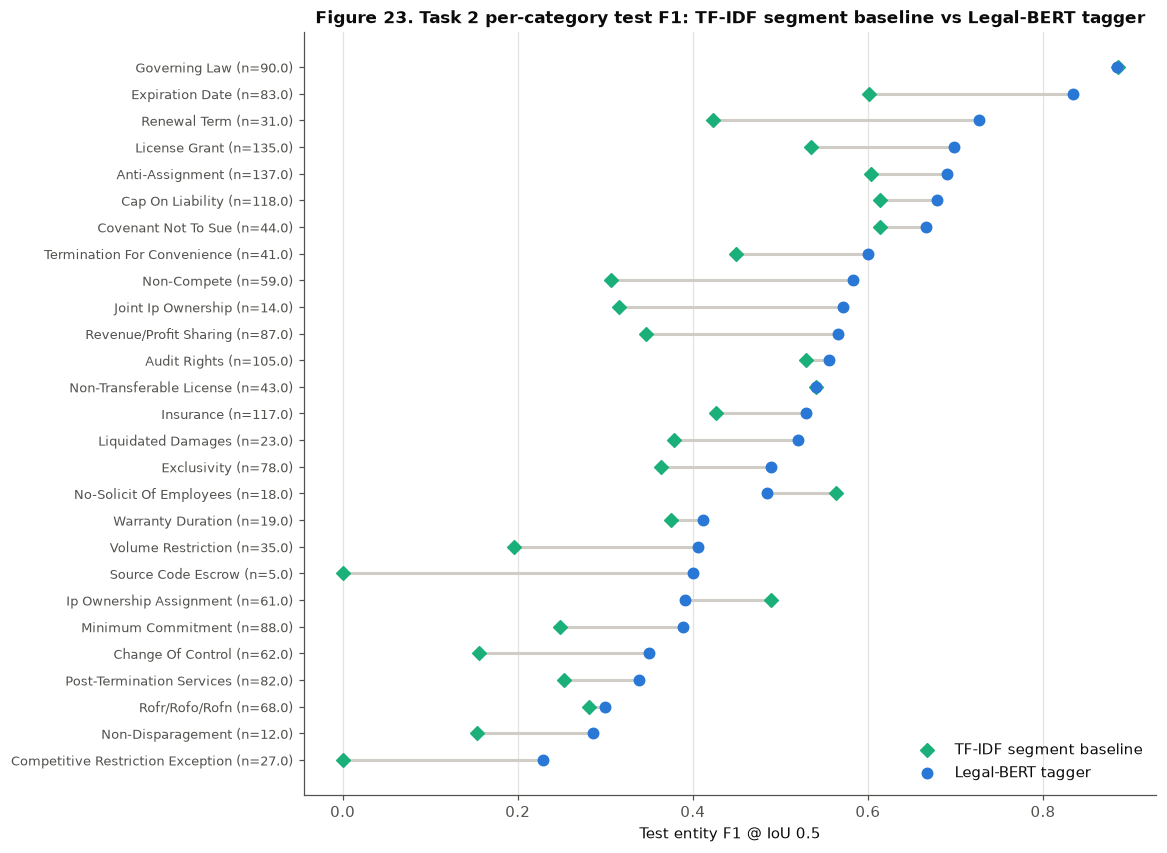

In [19]:
%%needs_models models/task2
# Per-category F1 with bootstrap CIs (resamples without the category skipped), both models
def per_cat_ci(cnt, n_boot=1000, seed=42):
    contracts = cnt.contract.unique()
    cube = (cnt.set_index(["contract", "category"])[["tp", "fp", "fn"]]
            .reindex(pd.MultiIndex.from_product([contracts, CATS])).fillna(0).to_numpy().reshape(len(contracts), K, 3))
    rng_ = np.random.default_rng(seed); boots = []
    for _ in range(n_boot):
        s = cube[rng_.integers(0, len(contracts), len(contracts))].sum(0)
        tp, fp, fn = s[:, 0], s[:, 1], s[:, 2]
        p = np.divide(tp, tp + fp, out=np.zeros(K), where=tp + fp > 0); r = np.divide(tp, tp + fn, out=np.zeros(K), where=tp + fn > 0)
        f = np.divide(2 * p * r, p + r, out=np.zeros(K), where=p + r > 0)
        boots.append(np.where(tp + fn > 0, f, np.nan))
    b = np.array(boots)
    return np.nanpercentile(b, 2.5, axis=0), np.nanpercentile(b, 97.5, axis=0)
pc = pd.DataFrame({"gold test spans": SUMM["t2_legalbert_tagger"]["per_category"].gold,
                   "train spans": spans[spans.split == "train"].category.value_counts().reindex(CATS),
                   "baseline F1": SUMM["t2_tfidf_segments"]["per_category"].f1, "tagger F1": SUMM["t2_legalbert_tagger"]["per_category"].f1,
                   "tagger P": SUMM["t2_legalbert_tagger"]["per_category"].precision, "tagger R": SUMM["t2_legalbert_tagger"]["per_category"].recall,
                   "tagger CUAD AUPR": pd.Series(PCAUPR["t2_legalbert_tagger"])})
lo, hi = per_cat_ci(CNT["t2_legalbert_tagger"])
pc["tagger 95% CI"] = [f"[{l:.2f}, {h:.2f}]" for l, h in zip(lo, hi)]
pc = pc.sort_values("tagger F1")
pc.to_csv(C.RESULTS_DIR / "task2_per_category.csv")
display(pc.round(3))
fig, ax = plt.subplots(figsize=(10, 9))
yy = np.arange(len(pc))
ax.hlines(yy, pc[["baseline F1", "tagger F1"]].min(axis=1), pc[["baseline F1", "tagger F1"]].max(axis=1), color="#cfcdc6", linewidth=2)
ax.scatter(pc["baseline F1"], yy, color=PL.AQUA, marker="D", s=40, label="TF-IDF segment baseline", zorder=3)
ax.scatter(pc["tagger F1"], yy, color=PL.BLUE, s=46, label="Legal-BERT tagger", zorder=3)
ax.set_yticks(yy); ax.set_yticklabels([f"{c} (n={n})" for c, n in zip(pc.index, pc["gold test spans"])], fontsize=8.5)
ax.set_xlabel("Test entity F1 @ IoU 0.5"); ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
ax.set_title("Figure 23. Task 2 per-category test F1: TF-IDF segment baseline vs Legal-BERT tagger", fontsize=11)
PL.savefig(fig, 23, "t2_per_category_f1"); plt.show()

In [20]:
%%needs_models models/task2
# Subgroups: contract length terciles and category-frequency terciles (tagger)
L = pd.Series({c: len(TEXT[c]) for c in SPLIT["test"]})
terc = pd.qcut(L, 3, labels=["short", "medium", "long"])
sub = []
for name in CNT:
    for t in ["short", "medium", "long"]:
        cc = list(L[terc == t].index)
        s = M.summarise(CNT[name][CNT[name].contract.isin(cc)], CATS)
        sub.append({"model": name, "subgroup": f"contract length: {t} ({L[terc == t].min():,}-{L[terc == t].max():,} chars, {len(cc)} contracts)",
                    "macro_f1": s["macro_f1"], "micro_f1": s["micro_f1"]})
    freq = spans[spans.split == "train"].category.value_counts().reindex(CATS)
    ft = pd.qcut(freq.rank(method="first"), 3, labels=["rare", "medium", "frequent"])
    per = SUMM[name]["per_category"]
    for t in ["rare", "medium", "frequent"]:
        cats_t = list(ft[ft == t].index)
        sub.append({"model": name, "subgroup": f"category frequency: {t} ({freq[cats_t].min()}-{freq[cats_t].max()} train spans)",
                    "macro_f1": float(per.loc[cats_t, "f1"].mean()), "micro_f1": np.nan})
sub = pd.DataFrame(sub); sub.to_csv(C.RESULTS_DIR / "task2_subgroups.csv", index=False)
display(sub.pivot_table(index="subgroup", columns="model", values="macro_f1").round(3))

model,t2_legalbert_tagger,t2_tfidf_segments
subgroup,,
category frequency: frequent (282-523 train spans),0.622,0.522
category frequency: medium (153-277 train spans),0.505,0.373
category frequency: rare (45-133 train spans),0.442,0.289
"contract length: long (40,590-300,768 chars, 34 contracts)",0.499,0.380
"contract length: medium (19,128-40,442 chars, 34 contracts)",0.519,0.393
"contract length: short (645-18,069 chars, 34 contracts)",0.631,0.448


**Interpretation of the test results (each model scored once; `results/task2_test_summary.csv`).**
* **The Legal-BERT tagger reaches macro-F1 0.523 at IoU 0.5** (95 % CI 0.490–0.560; micro-F1 0.575, macro precision 0.60, recall
  0.49) against **0.394** (0.367–0.431) for the TF-IDF segment baseline. **Objective O4 (first part) is met:** the paired
  contract-level bootstrap difference is **+0.129, CI [+0.099, +0.155]**.
* **Far below the ceilings:** the formulation allows 0.998 and the baseline's segmentation 0.859, so the gap is the models, not the
  format. Exact boundaries are much harder (tagger 0.300): the model usually finds the right region but not the annotator's exact
  first and last word.
* **No false alarms on clause-free contracts:** in the 9 test contracts without any of the 27 clause types, neither model predicts a
  single span.
* **Per category (Figure 23):** formulaic clauses are found well — Governing Law 0.88, Expiration Date 0.83, Renewal Term 0.73,
  License Grant 0.70 — while Competitive Restriction Exception (0.23), Non-Disparagement (0.29), Rofr/Rofo/Rofn (0.30) and
  Post-Termination Services (0.34) are hard. The tagger beats the baseline in 23 of the 27 categories (equal on Non-Transferable
  License; worse on IP Ownership Assignment, No-Solicit Of Employees and, by 0.001, Governing Law); the baseline finds no Competitive
  Restriction Exception or Source Code Escrow span at all.
* **Subgroups (`results/task2_subgroups.csv`):** both models do best on short contracts (tagger 0.63 vs 0.50 on long ones — more
  text means more places for false positives and for missed clauses) and on frequent categories (0.62 for the most frequent third
  vs 0.44 for the rarest third).
* **Budget:** training 7.2 min for the test run (8 epochs) and 39 min for the whole plan including variants and seeds; inference
  0.063 s per contract on the GPU (about 1 minute per 1,000 contracts).

## 7. Published comparison: the CUAD paper
The CUAD paper (Hendrycks et al., 2021) reports results on the same official test contracts. The numbers below were read
from the paper itself (Table 2, page 6; PDF from the NeurIPS Datasets & Benchmarks proceedings)
and are typed here from that table; our numbers come from `results/`. The paper gives
per-category AUPR only as a bar chart without values (Figure 4, page 7), so per-category comparison is by **rank only**.

### 7.1 Why recall stops near 58 %, and a low-threshold candidate set
The CUAD-style sweep ranks the *decoded* spans by their confidence (the mean INSIDE probability over the span's tokens).
At the tuned operating point (θ_inside = 0.6) every decoded span already has confidence ≥ 0.6 and tokens below 0.6 never
form a span, so lowering the confidence cut-off in the sweep cannot add new candidates: the curve ends at the recall of
the decoded set. To see the trade-off, the validation probabilities are decoded at θ_inside from 0.05 to 0.6 (θ_begin and
`min_tokens` fixed at their tuned values).

**Selection rule for the low-threshold set (fixed before looking at the sweep; validation only):** the θ_inside with the
highest **validation CUAD-style maximum recall**, among the values whose median predicted span length is at most twice the
median gold span length (a sanity condition: a very low threshold glues neighbouring clauses into very long spans, which is
not a usable candidate list); ties go to the higher θ. The resulting candidate set, ranked by confidence, is evaluated
**once on test** as a separate model `t2_legalbert_tagger_lowthr` for the threshold-free (AUPR / precision-at-recall)
analysis. **The main operating-point result of the tagger stays the 0.523 of section 6.**

In [21]:
%%needs_models models/task2
val_keys = [(c, k) for c in SPLIT["validation"] for k in CATS]
gold_len_med = float((gold_val.end - gold_val.start).median())
sweep, VCURVE = [], {}
for ti in [0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6]:
    pv = decode_contracts(VPROBS.get, SPLIT["validation"], ti, TH["theta_begin"], TH["min_tokens"])
    sm = M.summarise(M.count_table(gold_val, pv, SPLIT["validation"], CATS), CATS)
    cur = M.cuad_curve(gold_val, pv, text_of, val_keys); VCURVE[ti] = cur
    sweep.append({"theta_inside": ti, "predicted spans": len(pv), "median predicted length (chars)": float((pv.end - pv.start).median()),
                  "IoU0.5 micro precision": sm["micro_precision"], "IoU0.5 micro recall": sm["micro_recall"],
                  "IoU0.5 macro-F1": sm["macro_f1"], "IoU0.5 macro precision": sm["macro_precision"], "IoU0.5 macro recall": sm["macro_recall"], "CUAD-style max recall": max(r for r in cur["recalls"] if r == r),
                  "CUAD-style AUPR": cur["aupr"], "CUAD-style P@80%R": cur["prec_at_80_recall"]})
sweep = pd.DataFrame(sweep)
sweep["sensible (median length <= 2 x gold median)"] = sweep["median predicted length (chars)"] <= 2 * gold_len_med
print(f"Median gold span length on validation: {gold_len_med:.0f} characters")
display(sweep.round(4))
ok = sweep[sweep["sensible (median length <= 2 x gold median)"]]
best_low = ok.sort_values(["CUAD-style max recall", "theta_inside"], ascending=[False, False]).iloc[0]
TI_LOW = float(best_low.theta_inside)
print(f"Selected low threshold: theta_inside = {TI_LOW} -> validation CUAD-style max recall {best_low['CUAD-style max recall']:.3f} "
      f"(tuned 0.6: {sweep.set_index('theta_inside').loc[0.6, 'CUAD-style max recall']:.3f}), AUPR {best_low['CUAD-style AUPR']:.3f}")

# Why the tuned decoder misses spans: the highest INSIDE probability of the gold category inside each validation gold span
mx = []
for r in gold_val.itertuples():
    rr = D.span_token_range(corpus[r.contract]["offsets"], r.start, r.end)
    if rr:
        mx.append(float(VPROBS[r.contract][rr[0]:rr[1] + 1, CIDX[r.category]].max()))
mx = np.array(mx)
peak = pd.DataFrame({"highest INSIDE probability in the gold span is below": [0.6, 0.3, 0.1, 0.05],
                     "share of validation gold spans": [float((mx < t).mean()) for t in [0.6, 0.3, 0.1, 0.05]]})
display(peak.round(3))
json.dump({"selection_rule": "max validation CUAD-style max recall s.t. median predicted length <= 2 x median gold length; ties -> higher theta",
           "theta_inside_low": TI_LOW, "theta_begin": TH["theta_begin"], "min_tokens": TH["min_tokens"], "gold_median_length_chars": gold_len_med,
           "sweep": sweep.to_dict(orient="records"), "gold_span_peak_probability": peak.to_dict(orient="records")},
          open(C.RESULTS_DIR / "task2_recall_ceiling.json", "w"), indent=2, default=float)
sweep.to_csv(C.RESULTS_DIR / "task2_recall_ceiling_sweep.csv", index=False)
# Appendix table (report): macro-averaged values of the same sweep (Figure 24 shows the micro values)
macro_tab = sweep[["theta_inside", "IoU0.5 macro precision", "IoU0.5 macro recall", "IoU0.5 macro-F1"]]
macro_tab.to_csv(C.RESULTS_DIR / "task2_recall_ceiling_macro_appendix.csv", index=False)
print("Appendix table - macro-averaged precision / recall / F1 at IoU 0.5 by theta_inside (validation):")
display(macro_tab.round(4))

Median gold span length on validation: 283 characters


,theta_inside,predicted spans,median predicted length (chars),IoU0.5 micro precision,IoU0.5 micro recall,IoU0.5 macro-F1,IoU0.5 macro precision,IoU0.5 macro recall,CUAD-style max recall,CUAD-style AUPR,CUAD-style P@80%R,sensible (median length <= 2 x gold median)
0,0.05,2446,229.0,0.3107,0.6194,0.3942,0.3169,0.5860,0.6944,0.5866,0.0,True
1,0.10,1994,235.0,0.3781,0.6145,0.4541,0.3855,0.5922,0.6895,0.5904,0.0,True
2,0.15,1793,237.0,0.4161,0.6080,0.4761,0.4210,0.5821,0.6764,0.5876,0.0,True
3,0.20,1684,239.0,0.4406,0.6047,0.4929,0.4485,0.5817,0.6716,0.5857,0.0,True
4,0.30,1474,246.0,0.4925,0.5917,0.5163,0.4974,0.5674,0.6528,0.5758,0.0,True
5,0.40,1292,267.0,0.5557,0.5852,0.5438,0.5610,0.5552,0.6479,0.5758,0.0,True
6,0.50,1131,266.0,0.6207,0.5721,0.5630,0.6100,0.5436,0.6275,0.5545,0.0,True
7,0.60,1052,260.0,0.6559,0.5623,0.5652,0.6369,0.5272,0.6072,0.5395,0.0,True


Selected low threshold: theta_inside = 0.05 -> validation CUAD-style max recall 0.694 (tuned 0.6: 0.607), AUPR 0.587


,highest INSIDE probability in the gold span is below,share of validation gold spans
0,0.60,0.289
1,0.30,0.219
2,0.10,0.161
3,0.05,0.141


Appendix table - macro-averaged precision / recall / F1 at IoU 0.5 by theta_inside (validation):


,theta_inside,IoU0.5 macro precision,IoU0.5 macro recall,IoU0.5 macro-F1
0,0.05,0.3169,0.5860,0.3942
1,0.10,0.3855,0.5922,0.4541
2,0.15,0.4210,0.5821,0.4761
3,0.20,0.4485,0.5817,0.4929
4,0.30,0.4974,0.5674,0.5163
5,0.40,0.5610,0.5552,0.5438
6,0.50,0.6100,0.5436,0.5630
7,0.60,0.6369,0.5272,0.5652


In [22]:
%%needs_models models/task2
# The low-threshold candidate set on TEST (evaluated once; threshold-free analysis only)
if TPROBS is not None:
    lowthr_pred = decode_contracts(TPROBS.get, SPLIT["test"], TI_LOW, TH["theta_begin"], TH["min_tokens"])
else:
    lowthr_pred = pd.read_csv(C.RESULTS_DIR / "task2" / "t2_legalbert_tagger_lowthr_test_spans.csv")
n = "t2_legalbert_tagger_lowthr"
RES[n], CNT[n], SUMM[n], CURVE[n], PCAUPR[n] = full_metrics(lowthr_pred)
cfg_low = {"run": TEST_RUN, "theta_inside": TI_LOW, "theta_begin": TH["theta_begin"], "min_tokens": TH["min_tokens"],
           "purpose": "threshold-free analysis (AUPR, precision at recall); same weights and probabilities as t2_legalbert_tagger",
           "selection": "validation only, rule in section 7.1"}
C.test_once_spans(n, cfg_low, RES[n], lowthr_pred)
low_tab = pd.DataFrame([{"model": lab, "decoded spans": len(pred), "CUAD-style AUPR %": 100 * RES[m]["cuad_micro_aupr"],
                         "P@80%R %": 100 * RES[m]["cuad_prec_at_80_recall"], "P@90%R %": 100 * RES[m]["cuad_prec_at_90_recall"],
                         "max recall %": 100 * max(r for r in CURVE[m]["recalls"] if r == r),
                         "macro-F1 @ IoU0.5 (all spans kept)": RES[m]["macro_f1"]}
                        for lab, m, pred in [("tagger, tuned operating point (theta_i 0.6)", "t2_legalbert_tagger", ttest_pred),
                                             (f"tagger, low-threshold candidates (theta_i {TI_LOW})", n, lowthr_pred)]])
low_tab.to_csv(C.RESULTS_DIR / "task2_lowthr_test.csv", index=False)
display(low_tab.round(3))

[test] t2_legalbert_tagger_lowthr: already evaluated once (see test_eval_log.csv); re-run reproduced the identical spans, saved metrics re-used.


,model,decoded spans,CUAD-style AUPR %,P@80%R %,P@90%R %,max recall %,macro-F1 @ IoU0.5 (all spans kept)
0,"tagger, tuned operating point (theta_i 0.6)",1391,52.414,0.0,0.0,58.145,0.523
1,"tagger, low-threshold candidates (theta_i 0.05)",3260,58.743,0.0,0.0,69.025,0.410


**Interpretation (`results/task2_recall_ceiling.json`, `results/task2_lowthr_test.csv`).**
*Why recall stops near 58 %.* The decoder only turns tokens whose INSIDE probability is at least θ_inside into spans. On
validation, **28.9 %** of the gold spans contain *no* token with probability ≥ 0.6 for their category, so at the tuned setting
they cannot be found at all, whatever confidence cut-off the CUAD sweep uses. Of the remaining spans, some are merged with a
neighbour or found with boundaries too far off for the overlap criterion. Lowering θ_inside raises recall only slowly: CUAD-style
maximum recall goes from 0.607 (θ 0.6) to 0.694 (θ 0.05), and IoU-recall from 0.562 to 0.619, while precision at IoU 0.5 falls
from 0.656 to 0.311. The reason is that the model is *confidently wrong* on many missed spans: **14.1 %** of the validation gold
spans have no token above 0.05. No threshold can recover these; a different model, or more context, would be needed.

*The low-threshold candidate set.* The selection rule picked θ_inside = 0.05, the lowest value of the pre-declared grid. The
length condition never bound (low thresholds produce more, not longer, spans because `min_tokens` = 10 stays in force). The
recall gain flattens at the bottom of the grid (0.689 at θ 0.1 vs 0.694 at 0.05), so extending the grid further would add little.
Evaluated once on test as `t2_legalbert_tagger_lowthr`, the candidate list reaches **69.0 %** maximum recall (tuned: 58.1 %) and a
CUAD-style AUPR of **58.7 %** (tuned: 52.4 %). Precision at 80 % and 90 % recall is still 0: the curve never gets there. Its
macro-F1 at IoU 0.5 when every candidate is kept is only 0.410. That is expected (it is a ranked list for a reviewer, not an
operating point), and it is why **0.523 stays the main result**. In practice the two settings serve different users: the tuned
setting for an automatic first pass with few false alarms, the low-threshold list for a reviewer who would rather check more
candidates than miss a clause.

In [23]:
%%needs_models models/task2
paper = pd.DataFrame([("BERT-base", 32.4, 8.2, 0.0), ("RoBERTa-base", 42.6, 31.1, 0.0),
                      ("RoBERTa-base + Contracts Pretraining", 45.2, 34.1, 0.0), ("RoBERTa-large", 48.2, 38.1, 0.0),
                      ("DeBERTa-xlarge (best in paper)", 47.8, 44.0, 17.8)],
                     columns=["model", "AUPR %", "P@80%R %", "P@90%R %"]).assign(source="CUAD paper, Table 2 p. 6 (41 categories)")
ours = pd.DataFrame([(lab, 100 * RES[n]["cuad_micro_aupr"], 100 * RES[n]["cuad_prec_at_80_recall"], 100 * RES[n]["cuad_prec_at_90_recall"])
                     for lab, n in [("TF-IDF segment baseline (ours)", "t2_tfidf_segments"), ("Legal-BERT tagger (ours)", "t2_legalbert_tagger"),
                                    (f"Legal-BERT tagger, low-threshold candidates (ours, theta_i {TI_LOW})", "t2_legalbert_tagger_lowthr")]],
                    columns=["model", "AUPR %", "P@80%R %", "P@90%R %"]).assign(source="ours, CUAD-style evaluation (27 categories)")
cmp = pd.concat([paper, ours], ignore_index=True)
cmp["max recall reached %"] = [np.nan] * len(paper) + [100 * max(r for r in CURVE[n]["recalls"] if r == r)
                                                       for n in ["t2_tfidf_segments", "t2_legalbert_tagger", "t2_legalbert_tagger_lowthr"]]
cmp.to_csv(C.RESULTS_DIR / "task2_cuad_comparison.csv", index=False)
display(cmp.round(1))
print("Our CUAD-style curves stop at the recall reached by the decoded spans (last column); the paper's QA models produce "
      "n-best candidate answers and reach higher recall (they report precision at 90 % recall). The low-threshold row is our "
      "closest analogue of an n-best list. Not like-for-like: 27 vs 41 categories, windowed tagger vs extractive QA.")

# Rank comparison per category: paper's Figure 4 order (lowest to highest AUPR, DeBERTa-xlarge) vs our tagger's AUPR
paper_order = ["Covenant Not To Sue", "Ip Ownership Assignment", "Rofr/Rofo/Rofn", "Most Favored Nation", "Post-Termination Services",
               "Change Of Control", "Warranty Duration", "Competitive Restriction Exception", "Affiliate License-Licensor",
               "Unlimited/All-You-Can-Eat-License", "Non-Compete", "Joint Ip Ownership", "Minimum Commitment", "Non-Disparagement",
               "Affiliate License-Licensee", "Liquidated Damages", "Volume Restriction", "Third Party Beneficiary", "Uncapped Liability",
               "Non-Transferable License", "No-Solicit Of Customers", "Notice Period To Terminate Renewal", "Termination For Convenience",
               "Effective Date", "Revenue/Profit Sharing", "Audit Rights", "Renewal Term", "Exclusivity", "Irrevocable Or Perpetual License",
               "Source Code Escrow", "Insurance", "License Grant", "Cap On Liability", "No-Solicit Of Employees", "Anti-Assignment",
               "Expiration Date", "Agreement Date", "Parties", "Document Name", "Governing Law"]
shared = [c for c in paper_order if c in CATS]
from scipy.stats import spearmanr
paper_rank = pd.Series(range(len(shared)), index=shared)
our_aupr = pd.Series(PCAUPR["t2_legalbert_tagger"])[shared]
rho = spearmanr(paper_rank, our_aupr).correlation
print(f"{len(shared)} of our 27 categories appear in the paper's Figure 4. Spearman rank correlation between the paper's "
      f"category order and our tagger's per-category AUPR: {rho:.2f}")
json.dump({"shared_categories": len(shared), "spearman_rank_vs_paper_figure4": rho}, open(C.RESULTS_DIR / "task2_cuad_rank.json", "w"), indent=2)

,model,AUPR %,P@80%R %,P@90%R %,source,max recall reached %
0,BERT-base,32.4,8.2,0.0,"CUAD paper, Table 2 p. 6 (41 categories)",NaN
1,RoBERTa-base,42.6,31.1,0.0,"CUAD paper, Table 2 p. 6 (41 categories)",NaN
2,RoBERTa-base + Contracts Pretraining,45.2,34.1,0.0,"CUAD paper, Table 2 p. 6 (41 categories)",NaN
3,RoBERTa-large,48.2,38.1,0.0,"CUAD paper, Table 2 p. 6 (41 categories)",NaN
4,DeBERTa-xlarge (best in paper),47.8,44.0,17.8,"CUAD paper, Table 2 p. 6 (41 categories)",NaN
5,TF-IDF segment baseline (ours),40.2,0.0,0.0,"ours, CUAD-style evaluation (27 categories)",47.9
6,Legal-BERT tagger (ours),52.4,0.0,0.0,"ours, CUAD-style evaluation (27 categories)",58.1
7,"Legal-BERT tagger, low-threshold candidates (o...",58.7,0.0,0.0,"ours, CUAD-style evaluation (27 categories)",69.0


Our CUAD-style curves stop at the recall reached by the decoded spans (last column); the paper's QA models produce n-best candidate answers and reach higher recall (they report precision at 90 % recall). The low-threshold row is our closest analogue of an n-best list. Not like-for-like: 27 vs 41 categories, windowed tagger vs extractive QA.
27 of our 27 categories appear in the paper's Figure 4. Spearman rank correlation between the paper's category order and our tagger's per-category AUPR: 0.66


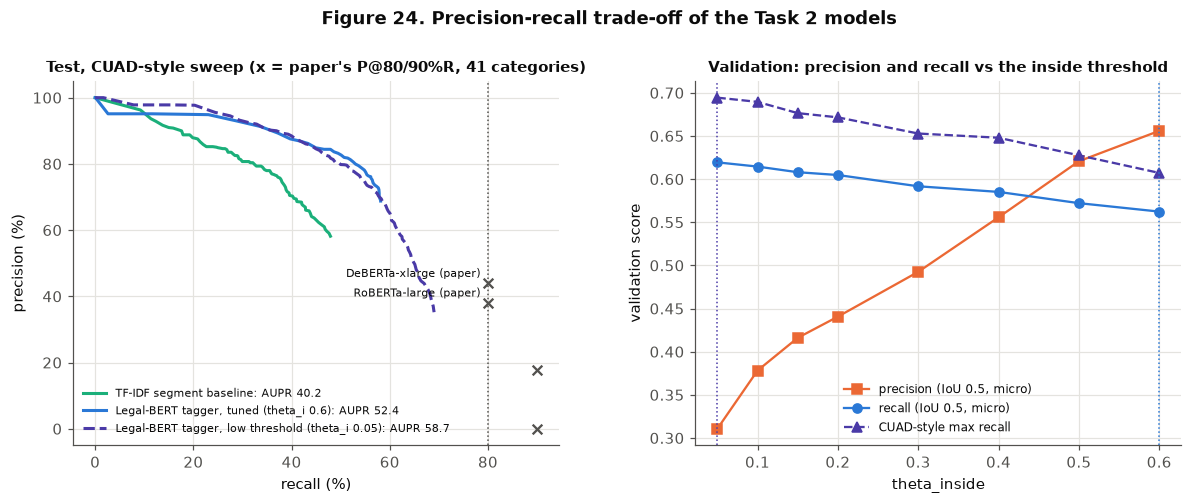

In [24]:
%%needs_models models/task2
# Figure 24: CUAD-style precision-recall curves on test (both tagger candidate sets and the baseline) and the validation sweep
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for name, col, ls, lab in [("t2_tfidf_segments", PL.AQUA, "-", "TF-IDF segment baseline"),
                           ("t2_legalbert_tagger", PL.BLUE, "-", "Legal-BERT tagger, tuned (theta_i 0.6)"),
                           ("t2_legalbert_tagger_lowthr", PL.VIOLET, "--", f"Legal-BERT tagger, low threshold (theta_i {TI_LOW})")]:
    cur = CURVE[name]
    axes[0].plot(np.array(cur["recalls"]) * 100, np.array(cur["precisions"]) * 100, ls, color=col, linewidth=2,
                 label=f"{lab}: AUPR {100 * cur['aupr']:.1f}")
for _, r in paper.iterrows():
    if r["model"].startswith(("RoBERTa-large", "DeBERTa")):
        axes[0].scatter([80, 90], [r["P@80%R %"], r["P@90%R %"]], marker="x", s=40, color=PL.INK_2)
        axes[0].annotate(r["model"].split(" (")[0] + " (paper)", (80, r["P@80%R %"]), textcoords="offset points", xytext=(-5, 4),
                         ha="right", fontsize=7)          # label to the left of the point, so it stays inside the left panel
axes[0].axvline(80, color=PL.INK_2, linestyle=":", linewidth=1)
axes[0].set_xlabel("recall (%)"); axes[0].set_ylabel("precision (%)"); axes[0].legend(fontsize=7.5, loc="lower left")
axes[0].set_title("Test, CUAD-style sweep (x = paper's P@80/90%R, 41 categories)", fontsize=10)
axes[1].plot(sweep.theta_inside, sweep["IoU0.5 micro precision"], "s-", color=PL.ORANGE, label="precision (IoU 0.5, micro)")
axes[1].plot(sweep.theta_inside, sweep["IoU0.5 micro recall"], "o-", color=PL.BLUE, label="recall (IoU 0.5, micro)")
axes[1].plot(sweep.theta_inside, sweep["CUAD-style max recall"], "^--", color=PL.VIOLET, label="CUAD-style max recall")
axes[1].axvline(TI_LOW, color=PL.VIOLET, linestyle=":", linewidth=1); axes[1].axvline(TH["theta_inside"], color=PL.BLUE, linestyle=":", linewidth=1)
axes[1].set_xlabel("theta_inside"); axes[1].set_ylabel("validation score"); axes[1].legend(fontsize=8)
axes[1].set_title("Validation: precision and recall vs the inside threshold", fontsize=10)
fig.subplots_adjust(wspace=0.28)
fig.suptitle("Figure 24. Precision-recall trade-off of the Task 2 models", fontweight="bold", y=1.03)
PL.savefig(fig, 24, "t2_precision_recall"); plt.show()

**Interpretation (Figure 24).** Left: on test, the tuned tagger keeps precision above about 85 % up to roughly 45 % recall
(CUAD-style counting) and its curve ends at 58 % recall; the baseline's precision falls steadily and ends at 48 % recall. The
low-threshold candidate list follows the tuned curve almost exactly up to 58 % recall, then continues to 69 % recall while its
precision drops to about 35 %. The crosses mark the paper's precision at 80 % and 90 % recall (41 categories). None of our curves
reaches that region, which is the main reason the AUPR numbers cannot be compared like-for-like. Right: on validation, raising
θ_inside trades recall for precision; precision climbs steeply while recall falls only slowly, which is why the F1 optimum sits
at the top of the range (0.6).

**Interpretation (`results/task2_cuad_comparison.csv`).** On the CUAD-style evaluation our tagger's AUPR is **52.4 %** (baseline
40.2 %), numerically above every model in the paper's Table 2 (best: RoBERTa-large 48.2 %, DeBERTa-xlarge 47.8 %). **This does
not mean it is better**, for three reasons:
1. **The curves cover different recall ranges.** The paper's QA models output many candidate answers per category with their
   probabilities, so the confidence sweep reaches high recall (DeBERTa-xlarge: 44.0 % precision at 80 % recall, 17.8 % at 90 %).
   Our decoder outputs a fixed set of spans, so our curve stops at the recall those spans reach — **58.1 %** for the tagger (47.9 %
   for the baseline) — and precision at 80 % / 90 % recall is therefore **0**. Our AUPR is high because precision is high over the
   part of the curve we cover (Figure 24), not because we find more clauses. Even the low-threshold candidate set of section 7.1
   (AUPR 58.7 %) stops at **69.0 %** recall and still has 0 precision at 80 % recall.
2. **Different category sets:** 27 vs 41 categories; several of the 14 we exclude (e.g. Parties, Document Name, dates) are easy,
   others (e.g. Most Favored Nation, Uncapped Liability) are rare and hard.
3. **Different models and training:** a windowed multi-label tagger on Legal-BERT-base trained on 343 contracts (65 held out for
   validation) vs extractive QA models up to DeBERTa-xlarge trained on all non-test contracts.
**Per category**, the paper gives only a bar chart (Figure 4), so we compare ranks: the Spearman correlation between the paper's
order of categories by AUPR and our tagger's per-category AUPR is **0.66** over the 27 shared categories. Largely the same
categories are easy (Governing Law, Expiration Date, Anti-Assignment, Cap On Liability) and hard (Competitive Restriction Exception,
Change Of Control, Post-Termination Services, Rofr/Rofo/Rofn, IP Ownership Assignment) for both approaches, which suggests that much
of the difficulty lies in the clauses themselves. The clearest disagreement is Covenant Not To Sue: the hardest category in the
paper's figure, but mid-table for our tagger (AUPR 0.64).

## 8. Representative outputs and error analysis
### 8.1 Error taxonomy over the whole test set (tagger)
Every unmatched gold span and every unmatched prediction is assigned to one cause, checked against the data:
**missed** (no prediction of that category overlaps it), **boundary too short / too long** (a same-category prediction
overlaps but IoU < 0.5), **split** (several predictions cover one gold span), **merged** (one prediction covers several gold
spans), **wrong category** (a prediction of another category matches it at IoU ≥ 0.5), **spurious** (a prediction overlapping
no gold span of any category; counted separately in the span-free contracts), **multi-category span partly found** (the gold
span carries several categories and only some were found), and **long span cut by the window** (gold span longer than one
window, 256 tokens).

model                                                    t2_legalbert_tagger  \
kind           cause                                                           
false negative boundary too long                                          10   
               boundary too short                                         64   
               boundary too short (long span > window)                     6   
               merged                                                    157   
               missed                                                    464   
               missed (long span > window)                                 4   
               split                                                      10   
               split (long span > window)                                  1   
               wrong category                                             82   
false positive boundary / split / merge (same category)                  139   
               spurious                                                  310   
               wrong category                                             58   

model                                                    t2_tfidf_segments  
kind           cause                                                        
false negative boundary too long                                        14  
               boundary too short                                       89  
               boundary too short (long span > window)                   5  
               merged                                                  108  
               missed                                                  688  
               missed (long span > window)                               8  
               split                                                    10  
               split (long span > window)                                3  
               wrong category                                           45  
false positive boundary / split / merge (same category)                155  
               spurious                                                418  
               wrong category                                           77

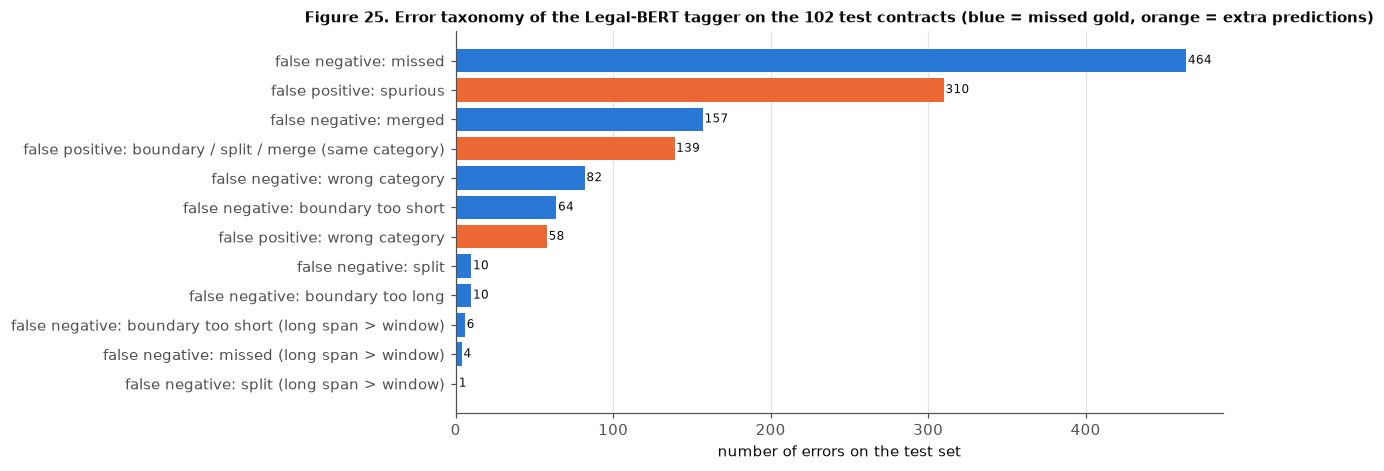

Per-category error counts of the tagger (report appendix): results/task2_error_taxonomy_per_category.csv


cause,FN: boundary too long,FN: boundary too short,FN: boundary too short (long span > window),FN: merged,FN: missed,FN: missed (long span > window),FN: split,FN: split (long span > window),FN: wrong category,FP: boundary / split / merge (same category),FP: spurious,FP: wrong category,total errors
category,,,,,,,,,,,,,
Insurance,0,2,0,44,15,0,1,0,0,13,23,0,98
Post-Termination Services,1,3,1,5,37,0,1,0,10,6,29,1,94
Audit Rights,1,1,0,18,28,0,0,0,0,4,37,2,91
Minimum Commitment,2,3,0,6,42,1,3,0,4,14,9,1,85
Rofr/Rofo/Rofn,0,6,0,14,27,0,0,0,3,9,21,4,84
Anti-Assignment,1,0,0,15,30,1,0,0,3,3,17,8,78
License Grant,0,4,0,11,27,0,0,0,6,8,18,1,75
Exclusivity,0,5,0,2,23,0,0,0,14,6,17,4,71
Cap On Liability,0,3,1,21,19,2,0,0,1,7,12,1,67


In [25]:
%%needs_models models/task2
def taxonomy(pred, name):
    rows = []
    g_all = gold_test
    for c in SPLIT["test"]:
        gc, pcn = g_all[g_all.contract == c], pred[pred.contract == c]
        offs = corpus[c]["offsets"]
        for k in CATS:
            gl = list(zip(gc[gc.category == k].start, gc[gc.category == k].end, gc[gc.category == k].n_categories_on_span))
            pl = list(zip(pcn[pcn.category == k].start, pcn[pcn.category == k].end, pcn[pcn.category == k].confidence))
            tp, fp, fn, pairs = M.match([(s, e) for s, e, _ in gl], pl)
            mg = {j for _, j in pairs}; mp = {i for i, _ in pairs}
            for j, (s, e, ncat) in enumerate(gl):
                if j in mg:
                    continue
                ov = [p for p in pl if min(p[1], e) > max(p[0], s)]
                other = pcn[(pcn.category != k)]
                wrong = any(M.char_iou((r.start, r.end), (s, e)) >= 0.5 for r in other.itertuples())
                rng_ = D.span_token_range(offs, s, e); long_ = rng_ and (rng_[1] - rng_[0] + 1) > 256
                if len(ov) >= 2:
                    cause = "split"
                elif len(ov) == 1:
                    p = ov[0]
                    covers = sum(1 for s2, e2, _ in gl if min(p[1], e2) > max(p[0], s2))
                    cause = "merged" if covers >= 2 else ("boundary too short" if (p[1] - p[0]) < (e - s) else "boundary too long")
                elif wrong:
                    cause = "wrong category"
                elif ncat > 1:
                    cause = "multi-category span partly found" if any(
                        M.char_iou((r.start, r.end), (s, e)) >= 0.5 for r in pcn.itertuples()) else "missed"
                else:
                    cause = "missed"
                if long_ and cause in ("missed", "split", "boundary too short"):
                    cause += " (long span > window)"
                rows.append({"model": name, "contract": c, "category": k, "kind": "false negative", "cause": cause, "start": s, "end": e,
                             "confidence": np.nan})
            for i, p in enumerate(pl):
                if i in mp:
                    continue
                same = any(min(p[1], e) > max(p[0], s) for s, e, _ in gl)
                anyg = any(min(p[1], r.end) > max(p[0], r.start) for r in gc.itertuples())
                cause = ("boundary / split / merge (same category)" if same else
                         "wrong category" if anyg else
                         "spurious (span-free contract)" if c in SPAN_FREE_TEST else "spurious")
                rows.append({"model": name, "contract": c, "category": k, "kind": "false positive", "cause": cause, "start": p[0], "end": p[1],
                             "confidence": p[2]})
    return pd.DataFrame(rows)
ERR = pd.concat([taxonomy(btest_pred, "t2_tfidf_segments"), taxonomy(ttest_pred, "t2_legalbert_tagger")], ignore_index=True)
ERR.to_csv(C.RESULTS_DIR / "task2_error_taxonomy.csv", index=False)
tax = ERR.groupby(["model", "kind", "cause"]).size().unstack(0).fillna(0).astype(int)
display(tax)
tt = ERR[ERR.model == "t2_legalbert_tagger"].groupby(["kind", "cause"]).size().sort_values()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh([f"{k}: {c}" for k, c in tt.index], tt.values, color=[PL.ORANGE if k == "false positive" else PL.BLUE for k, _ in tt.index])
for i, v in enumerate(tt.values):
    ax.text(v + 1, i, str(v), va="center", fontsize=8)
ax.set_xlabel("number of errors on the test set"); ax.grid(axis="y", visible=False)
ax.set_title("Figure 25. Error taxonomy of the Legal-BERT tagger on the 102 test contracts (blue = missed gold, orange = extra predictions)", fontsize=10)
PL.savefig(fig, 25, "t2_error_taxonomy"); plt.show()
# Per-category breakdown for the report appendix (overall counts go in the report body)
ptax = (ERR[ERR.model == "t2_legalbert_tagger"].assign(cause=lambda d: d.kind.map({"false negative": "FN", "false positive": "FP"}) + ": " + d.cause)
        .pivot_table(index="category", columns="cause", values="start", aggfunc="count", fill_value=0))
ptax["total errors"] = ptax.sum(axis=1)
ptax = ptax.sort_values("total errors", ascending=False)
ptax.to_csv(C.RESULTS_DIR / "task2_error_taxonomy_per_category.csv")
print("Per-category error counts of the tagger (report appendix): results/task2_error_taxonomy_per_category.csv")
display(ptax.head(10))

**Interpretation (`results/task2_error_taxonomy.csv`, Figure 25).** Of the tagger's 798 missed gold spans, **464 are simply
missed** (no prediction of that category nearby), **157 are merged** (one prediction covers several touching gold spans of the same
category — CUAD annotators often highlight each sentence of a clause separately, the model predicts the whole clause), 82 are found
under a **wrong category**, 70 have a **boundary that is too short** and 21 are split or too long; only 11 involve gold spans longer
than one 256-token window, so the window size is not a main cause. Of the 507 extra predictions, **310 are spurious** (they overlap
no gold span — some are genuine clauses the annotators did not mark, see 8.2), 139 are the counterpart of boundary, split and merge
errors and 58 are a wrong category. Compared with the baseline, the tagger misses far fewer spans (464 vs 688) and makes fewer
spurious predictions (310 vs 418), but it merges touching spans more often (157 vs 108).

### 8.2 Representative outputs: gold vs predicted spans
Ten test excerpts of varied categories. For each, the gold span(s) and the tagger's prediction(s) of that category in the
same region are shown with their confidence (texts shortened).

In [26]:
%%needs_models models/task2
def show(c, k, width=230):
    g = gold_test[(gold_test.contract == c) & (gold_test.category == k)]
    p = ttest_pred[(ttest_pred.contract == c) & (ttest_pred.category == k)]
    print(f"=== {k} | {c[:70]}")
    for r in g.itertuples():
        print(f"  GOLD [{r.start}-{r.end}]: {TEXT[c][r.start:r.end][:width]!r}")
    for r in p.itertuples():
        best = max([M.char_iou((r.start, r.end), (x.start, x.end)) for x in g.itertuples()], default=0)
        print(f"  PRED [{r.start}-{r.end}] conf {r.confidence:.2f} IoU {best:.2f}: {TEXT[c][r.start:r.end][:width]!r}")
    if p.empty:
        print("  PRED: none")
rng_ = np.random.default_rng(7)
cats_show = ["Governing Law", "Cap On Liability", "License Grant", "Non-Transferable License", "Exclusivity", "Change Of Control",
             "Liquidated Damages", "Renewal Term", "Audit Rights", "Competitive Restriction Exception"]
for k in cats_show:
    cands = gold_test[gold_test.category == k].contract.unique()
    show(cands[rng_.integers(len(cands))], k)

=== Governing Law | WEBHELPCOMINC_03_22_2000-EX-10.8-HOSTING AGREEMENT
  GOLD [17241-17391]: 'This Agreement shall be governed by and construed in accordance with the laws of the State of California exclusive of its conflict of laws principles.'
  PRED [17241-17391] conf 0.96 IoU 1.00: 'This Agreement shall be governed by and construed in accordance with the laws of the State of California exclusive of its conflict of laws principles.'
=== Cap On Liability | PHLVARIABLEINSURANCECOCT_08_17_2009-EX-10.1-STRATEGIC ALLIANCE AGREEME
  GOLD [61730-62036]: 'Each Investors Capital  Party acknowledges that none of the PHL Parties or their Affiliates shall be deemed to have guaranteed the  profitability of the GIE or any volume of sales, and no indemnification shall arise based on an as'
  GOLD [65926-66186]: 'Each PHL Party acknowledges that neither ICAS nor any of its Affiliates shall be  deemed to have guaranteed the profitability of the GIE or any volume of sales, and no indemnification shal

**Interpretation of the ten examples.**
1. *Governing Law* — found exactly (IoU 1.00, confidence 0.96): a formulaic clause.
2. *Cap On Liability* — the classic "IN NO EVENT SHALL ANY PARTY BE LIABLE…" exclusion is found exactly, but two clauses saying that
   no party guarantees profitability ("no indemnification shall arise…") are missed: unusual wording for a liability cap.
3. *License Grant* — the annotated grant is found exactly, plus an almost identical grant paragraph earlier in the same contract that
   is not annotated: counted as a false positive although it reads like a genuine licence grant (incomplete annotation).
4. *Non-Transferable License* — the right clause, but the prediction stops after 338 of 832 characters (IoU 0.41 < 0.5): a boundary
   error that the IoU criterion counts as both a miss and a false positive.
5. *Exclusivity* — one clause found exactly; a second prediction is only the fragment "PPI hereby grants EKR the exclusive" (the
   rest of the sentence fell below the inside threshold); the "appoints … as the exclusive distributor" clause is missed.
6. *Change Of Control* — the model marks only the sentence that defines a change of control as an assignment (IoU 0.14), while the
   annotator highlighted the whole long anti-assignment section: a disagreement about granularity.
7. *Liquidated Damages* — two of three clauses found exactly; the early-termination-fee clause is missed, and a definition of
   "Estimated Remaining Value" is predicted instead (related wording, wrong place).
8. *Renewal Term* — the clause is split into two predictions; the first just reaches IoU 0.50 and counts as correct, the second is a
   false positive, and a capitalised "intent not to renew" notice elsewhere is a further false positive.
9. *Audit Rights* — found exactly.
10. *Competitive Restriction Exception* — neither "Notwithstanding … shall not apply" exception is found: short, redacted ("[***]")
    clauses whose meaning depends on the clause they modify.

### 8.3 Five incorrect or low-quality outputs of the best model, with their causes
Selected from the taxonomy above (one of each frequent error type, plus a spurious prediction in a span-free contract);
the cause stated under each was checked by reading the excerpt.

In [27]:
%%needs_models models/task2
tag_err = ERR[ERR.model == "t2_legalbert_tagger"]
picks = []
for kind, cause in [("false negative", "missed"), ("false negative", "boundary too short"), ("false negative", "split"),
                    ("false positive", "wrong category"), ("false positive", "spurious (span-free contract)"),
                    ("false negative", "merged")]:
    cand = tag_err[(tag_err.kind == kind) & tag_err.cause.str.startswith(cause)]
    if len(cand):
        picks.append(cand.sort_values(["category", "start"]).iloc[len(cand) // 2])
for i, r in enumerate(picks, 1):
    c, k = r.contract, r.category
    print(f"--- Error {i}: {r.kind}, cause = {r.cause}, category = {k}, contract = {c[:60]}")
    lo_, hi_ = max(0, int(r.start) - 120), int(r.end) + 120
    print(f"  excerpt: {TEXT[c][lo_:hi_][:600]!r}")
    g = gold_test[(gold_test.contract == c) & (gold_test.start < hi_) & (gold_test.end > lo_)]
    for x in g.itertuples():
        print(f"  gold   : {x.category} [{x.start}-{x.end}] {TEXT[c][x.start:x.end][:200]!r}")
    p = ttest_pred[(ttest_pred.contract == c) & (ttest_pred.start < hi_) & (ttest_pred.end > lo_)]
    for x in p.itertuples():
        print(f"  pred   : {x.category} [{x.start}-{x.end}] conf {x.confidence:.2f} {TEXT[c][x.start:x.end][:200]!r}")
# The cause of each error, checked by reading the excerpts above (interpretation below); saved for the report's table
VERIFIED = {"missed": "A follow-on sentence of a grant without the usual cue words (\"hereby grants\", \"license\"); the neighbouring "
                      "grant sentences were found.",
            "boundary too short": "The gold span starts at the heading and includes the payment table; the prediction starts one "
                                  "sentence later and stops before the table of amounts, so the overlap stays below IoU 0.5.",
            "split": "One non-compete sentence is predicted as two pieces: the middle tokens fell just below the inside threshold.",
            "wrong category": "Inside a long Cap On Liability clause, an extra commission payable on termination reads like a "
                              "liquidated-damages payment (money-on-termination wording).",
            "merged": "The annotators highlighted each sentence of the insurance clause separately; the tagger predicts one long span "
                      "because the BEGIN markers did not fire at the sentence starts."}
rows = []
for i, r in enumerate(picks, 1):
    key = next(k for k in VERIFIED if r.cause.startswith(k))
    span = re.sub(r"\s+", " ", TEXT[r.contract][int(r.start):int(r.end)]).strip()
    rows.append({"error": i, "category": r.category, "error type": f"{r.kind}: {r.cause}", "contract": r.contract,
                 "start": int(r.start), "end": int(r.end), "excerpt": span[:297] + ("..." if len(span) > 300 else span[297:]),
                 "verified cause": VERIFIED[key]})
pd.DataFrame(rows).to_csv(C.RESULTS_DIR / "task2_error_examples.csv", index=False)
print(f"saved {len(rows)} examples -> results/task2_error_examples.csv")

--- Error 1: false negative, cause = missed, category = License Grant, contract = PACIRA PHARMACEUTICALS, INC. - A_R STRATEGIC LICENSING, DIST
  excerpt: "ts necessary to manufacture and supply the Products to EKR in accordance with this Agreement and the  Supply Agreement. Such grant by PPI shall include the right of EKR to market the Product in the Territory during the Term as an EKR  product using in addition to the Trademarks, EKR's own trademarks, trade dress, trade names and other proprietary designations in  combination with the Trademarks.   2.3 Grant of Trademark Rights. PPI hereby grants to EKR a royalty free and exclusive license (with the right to subli"
  gold   : Exclusivity [15906-16437] 'PPI hereby grants EKR the exclusive right and license (with the right to sublicense) to use, market, promote, sell, distribute and warehouse the Products (the "Distribution Rights") in the Field in th'
  gold   : License Grant [15906-16437] 'PPI hereby grants EKR the exclusive right and

**Causes of the five errors (checked by reading the excerpts).**
1. **Missed (License Grant):** "Such grant by PPI shall include the right of EKR to market the Product…" continues the previous
   grant sentence without the usual cue words ("hereby grants", "license"); the model found the neighbouring grants but not this
   follow-on sentence.
2. **Boundary too short (Minimum Commitment):** the gold span starts at the heading "Guaranteed Minimum Royalty during the Second
   Additional Term" and includes the payment table; the prediction starts one sentence later and stops before the table of amounts,
   which has no clause-like wording (IoU < 0.5).
3. **Split (Non-Compete):** one non-compete sentence is predicted as two pieces with confidence 0.65, just above the 0.6 threshold —
   tokens in the middle ("or otherwise authorize the use of her name, likeness or image in connection") fell below it.
4. **Wrong category (Liquidated Damages instead of Cap On Liability):** inside a long Cap On Liability clause, the text about an
   "Additional Commission Amount" payable on termination reads like a liquidated-damages payment; the confusable money-on-termination
   wording misleads the model.
5. **Merged (Insurance):** four touching gold spans (the annotators highlighted each sentence of the insurance clause separately) are
   predicted as one long span (confidence 0.97). The BEGIN probabilities did not fire at the sentence starts, because in many
   training contracts the same kind of clause is annotated as one span.
**Common patterns:** annotation granularity (merge/split and long-section vs single-sentence highlighting), boundaries at headings
and tables, follow-on sentences without cue words, and money-related wording shared by Cap On Liability, Liquidated Damages and
Revenue/Profit Sharing.

In [28]:
%%needs_models models/task2
free = ttest_pred[ttest_pred.contract.isin(SPAN_FREE_TEST)]
print(f"Span-free test contracts: {len(SPAN_FREE_TEST)}; the tagger predicts nothing in {len(SPAN_FREE_TEST) - free.contract.nunique()} of them "
      f"and {len(free)} spurious spans in the other {free.contract.nunique()} (categories: {free.category.value_counts().to_dict()})")

Span-free test contracts: 9; the tagger predicts nothing in 9 of them and 0 spurious spans in the other 0 (categories: {})


## 9. DEMO — extract clauses from any contract text
`extract_clauses(text_or_title)` takes **any pasted contract text** (or the title of a CUAD contract), runs the saved tagger
with the validation-tuned thresholds and prints the clauses it finds, with category and confidence. If the model weights are
not present (e.g. on Colab without training), it says so and shows the **saved output of the real run**: the saved test
predictions for a CUAD test contract, or the saved live output for a text the demo has run before (`results/demo_cache.json`).

In [29]:
# DEMO setup: everything the demo needs, loaded from saved files, so this group also runs on its own after the setup cell
RUN_DIR = ROOT / "models" / "task2" / json.load(open(C.RESULTS_DIR / "task2_choice.json"))["test_run"]
TH = json.load(open(C.RESULTS_DIR / "task2_thresholds.json"))
ttest_pred = pd.read_csv(C.RESULTS_DIR / "task2" / "t2_legalbert_tagger_test_spans.csv")

In [30]:
_DEMO = {}
def extract_clauses(text_or_title, max_chars=220, show=True):
    if text_or_title in TEXT:
        title, text = text_or_title, TEXT[text_or_title]
    else:
        title, text = None, text_or_title
    t0 = time.perf_counter()
    if (RUN_DIR / "best").exists():
        if "model" not in _DEMO:
            from transformers import AutoModelForTokenClassification
            _DEMO["model"] = AutoModelForTokenClassification.from_pretrained(RUN_DIR / "best").to("cuda" if torch.cuda.is_available() else "cpu").eval()
        model = _DEMO["model"]; dev = next(model.parameters()).device
        ids, offs = D.tokenize_contract(text, tok)
        wins = D.make_windows(len(ids), 256, 128); probs = []
        with torch.no_grad():
            for s, e in wins:
                x = torch.tensor([[tok.cls_token_id] + ids[s:e] + [tok.sep_token_id]], device=dev)
                with torch.autocast(device_type=dev.type, dtype=torch.bfloat16, enabled=dev.type == "cuda"):
                    p = torch.sigmoid(model(input_ids=x).logits.float())[0, 1:-1].cpu().numpy()
                probs.append(p)
        P = D.average_window_probs(len(ids), wins, probs, 2 * K)
        found = [(CATS[k], int(s), int(e), float(conf)) for k, s, e, conf in D.decode(P, offs, K, TH["theta_inside"], TH["theta_begin"], TH["min_tokens"])]
        src = "live model"
        C.demo_cache_put("task2", text, found)          # lets the demo show this real output where models/ is absent
    elif title is not None and title in set(ttest_pred.contract):
        found = [(r.category, r.start, r.end, r.confidence) for r in ttest_pred[ttest_pred.contract == title].itertuples()]
        src = "SAVED test predictions of the real run (model weights not available)"
    elif C.demo_cache_get("task2", text) is not None:
        found = [tuple(f) for f in C.demo_cache_get("task2", text)]
        src = "SAVED output of the live model from the real run (model weights not available)"
    else:
        print("Model weights not available and the text is not a CUAD test contract: nothing to show."); return [], "none"
    found = sorted(found, key=lambda x: x[1])
    if show:
        print(f"{len(found)} clauses found in {time.perf_counter() - t0:.1f} s ({src}); {len(text):,} characters")
        for cat, s, e, conf in found:
            print(f"  [{cat}] conf {conf:.2f}: {text[s:e][:max_chars]!r}")
    return found, src

sample = ("This Agreement shall be governed by and construed in accordance with the laws of the State of New York. "
          "Neither party may assign this Agreement without the prior written consent of the other party. "
          "In no event shall either party's aggregate liability under this Agreement exceed the fees paid in the twelve months "
          "preceding the claim. Licensor hereby grants to Licensee a non-exclusive, non-transferable license to use the Software.")
_ = extract_clauses(sample)

W1113 18:42:52.954000 17040 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:  43%|████▎     | 86/199 [00:00<00:00, 853.47it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1450.73it/s]

5 clauses found in 0.9 s (live model); 432 characters
  [Governing Law] conf 0.97: 'This Agreement shall be governed by and construed in accordance with the laws of the State of New York.'
  [Anti-Assignment] conf 0.97: 'Neither party may assign this Agreement without the prior written consent of the other party.'
  [Cap On Liability] conf 0.98: "In no event shall either party's aggregate liability under this Agreement exceed the fees paid in the twelve months preceding the claim."
  [License Grant] conf 0.93: 'Licensor hereby grants to Licensee a non-exclusive, non-transferable license to use the Software.'
  [Non-Transferable License] conf 0.97: 'Licensor hereby grants to Licensee a non-exclusive, non-transferable license to use the Software.'


In [31]:
# A real, unseen test contract, chosen by a fixed rule (never used for any decision): among the test contracts under
# 40,000 characters, the one with the most distinct gold clause types (ties: the shorter contract)
gold_t = spans[spans.split == "test"]
n_types = gold_t.groupby("contract").category.nunique()
cands = [c for c in SPLIT["test"] if len(TEXT[c]) < 40_000 and c in n_types.index]
demo_c = min(cands, key=lambda c: (-n_types[c], len(TEXT[c])))
gold_c = gold_t[gold_t.contract == demo_c]
found, src = extract_clauses(demo_c, show=False)
match = lambda k, s, e: any(M.char_iou((s, e), (a, b)) >= 0.5 for a, b in zip(gold_c[gold_c.category == k].start, gold_c[gold_c.category == k].end))
rows = [{"type": k, "confidence": round(conf, 2), "excerpt": re.sub(r"\s+", " ", TEXT[demo_c][s:e]).strip()[:110] + "...",
         "matches a gold span (IoU >= 0.5)": "yes" if match(k, s, e) else "no"} for k, s, e, conf in found]
print(f"Test contract: {demo_c[:80]} ({len(TEXT[demo_c]):,} characters; {len(gold_c)} gold spans of {gold_c.category.nunique()} types)")
print(f"{len(found)} clauses extracted ({src}); {sum(r['matches a gold span (IoU >= 0.5)'] == 'yes' for r in rows)} of them match a gold span")
with pd.option_context("display.max_colwidth", 120):
    display(pd.DataFrame(rows))
missed = sorted(set(gold_c.category) - {r["type"] for r in rows if r["matches a gold span (IoU >= 0.5)"] == "yes"})
print("Gold types without a matching extraction:", ", ".join(missed) if missed else "none")
# second case: a test contract with none of the 27 clause types (the shortest one)
empty_c = min(SPLIT["test"], key=lambda c: len(TEXT[c]))
print(f"A contract with none of the 27 types ({empty_c[:45]}..., {len(gold_t[gold_t.contract == empty_c])} gold spans): "
      f"{len(extract_clauses(empty_c, show=False)[0])} clauses returned")

Test contract: WOMENSGOLFUNLIMITEDINC_03_29_2000-EX-10.13-ENDORSEMENT AGREEMENT (32,371 characters; 41 gold spans of 14 types)
25 clauses extracted (live model); 21 of them match a gold span


,type,confidence,excerpt,matches a gold span (IoU >= 0.5)
0,Expiration Date,0.92,"The term of this Agreement shall begin on January 1, 2000 and continue for an initial period of five (5) years...",yes
1,Exclusivity,0.99,"The Professional hereby grants to the Company an exclusive license to use her name, likeness, image and person...",no
2,License Grant,0.79,"The Professional hereby grants to the Company an exclusive license to use her name, likeness, image and person...",yes
3,Volume Restriction,0.84,The Professional agrees to serve as a professional golf instructor during up to ten (10) golf clinics hosted b...,yes
4,Volume Restriction,0.70,The Professional agrees to serve as a spokesperson for the Company at up to two (2) Professional Golf Associat...,yes
5,Exclusivity,0.99,"The Professional hereby grants to the Company the exclusive and worldwide right to use her name, likeness, ima...",yes
6,License Grant,0.71,"The Professional hereby grants to the Company the exclusive and worldwide right to use her name, likeness, ima...",yes
7,Ip Ownership Assignment,0.76,The Professional agrees that the Company shall own all such materials and all intellectual property rights&bbs...,no
8,License Grant,0.96,The Professional hereby grants to the Company the worldwide right during the Term and for a period of six (6) ...,yes
9,Exclusivity,0.99,"The Professional hereby grants to the Company an exclusive license to use her name, likeness, image and person...",yes


Gold types without a matching extraction: Non-Disparagement
A contract with none of the 27 types (RMRGROUPINC_01_22_2020-EX-99.1-JOINT FILING A..., 0 gold spans): 0 clauses returned


The demo runs the saved tagger on a short made-up text in under a second and finds all five clauses, including the double label
*License Grant* + *Non-Transferable License* on the same sentence (multi-label output). On the real test contract, chosen by the
fixed rule above, each extracted clause is checked against the lawyers' spans: the table shows which extractions match a gold span
(IoU ≥ 0.5) and which gold types were not found, so the demo shows both what the tagger gets right and what it misses. On a
contract that contains none of the 27 clause types it returns nothing.

## 10. Conclusion and limitations of Task 2

* **What was built:** clause extraction as multi-label sequence labelling over sliding windows, with INSIDE + BEGIN targets
  (formulation ceiling 0.998), a TF-IDF segment baseline (segmentation ceiling 0.859) and a Legal-BERT tagger.
* **Result:** the tagger reaches **0.523 macro-F1 at IoU 0.5** on the 102 official test contracts (baseline 0.394; difference +0.129
  [+0.099, +0.155], objective O4 met for the baseline comparison), with no false alarms on clause-free contracts, and high precision
  over the recall range it reaches (CUAD-style AUPR 52.4 %, maximum recall 58 %).
* **Limitations:** (1) annotation boundaries are subjective — sentence-by-sentence vs whole-section highlighting explains many
  merge/split and boundary errors, and exact-boundary F1 is only 0.30; (2) only 27 of CUAD's 41 categories; (3) English, US,
  SEC-filed contracts; (4) 256-token windows lose long-range context (a clause whose meaning depends on a distant definition);
  (5) rare categories have 5–27 test spans, so their scores are very uncertain; (6) recall is capped: at the tuned setting the
  curve ends at 58 % recall, and even the low-threshold candidate list (section 7.1) only reaches 69 %, because the model gives
  14 % of the gold spans (validation) no token probability above 0.05 — unlike the QA models of the CUAD paper, we never reach
  80 % recall; (7) a 384/192 window did not help on validation (one seed).
* **Future work:** a model that ranks candidate spans directly (e.g. an extractive-QA head with n-best answers per category) to
  reach higher recall; longer windows or a long-document
  model; a span-merging rule learned from the annotation style; and using Task 1's classifier to re-check the category of each
  extracted span (Part F pipeline).

## 11. Evaluation summary (Part C)
**Metrics and the cost of errors.** A reviewer who uses the extractor loses most when a clause is *not found* (it may never be
read); a spurious span costs a few seconds to dismiss. We therefore report entity-level recall and precision separately, use
CUAD's IoU ≥ 0.5 criterion (annotation boundaries are subjective — exact match is the strict secondary number), take
**macro-F1 over the 27 categories** as primary (rare risk categories count as much as frequent ones), and add CUAD-style
**AUPR and precision at 80 % / 90 % recall**, which describe the trade-off a reviewer faces when they want most clauses found.
The full justification for both tasks is in `202609212_Task1.ipynb`, section 7.1.

**Second (small) ablation — INSIDE-only vs INSIDE+BEGIN labels.** The oracle check of section 2.5 isolates the BEGIN markers:
decoding the gold labels with BEGIN gives a ceiling of 0.998 macro-F1 at IoU 0.5, without BEGIN 0.932 — the BEGIN markers are
needed because touching same-category clauses would otherwise merge.

In [32]:
%%needs_models models/task2
oracle_all = json.load(open(C.RESULTS_DIR / "task2_oracle.json"))
low = pd.read_csv(C.RESULTS_DIR / "task2_lowthr_test.csv")
T2_SUM = pd.DataFrame([
    {"model": "TF-IDF segment baseline", "macro-F1 @ IoU0.5": RES["t2_tfidf_segments"]["macro_f1"], "exact macro-F1": RES["t2_tfidf_segments"]["exact_macro_f1"],
     "CUAD-style AUPR": RES["t2_tfidf_segments"]["cuad_micro_aupr"], "max recall": max(r for r in CURVE["t2_tfidf_segments"]["recalls"] if r == r)},
    {"model": "Legal-BERT tagger (main result)", "macro-F1 @ IoU0.5": RES["t2_legalbert_tagger"]["macro_f1"], "exact macro-F1": RES["t2_legalbert_tagger"]["exact_macro_f1"],
     "CUAD-style AUPR": RES["t2_legalbert_tagger"]["cuad_micro_aupr"], "max recall": max(r for r in CURVE["t2_legalbert_tagger"]["recalls"] if r == r)},
    {"model": "ANALYSIS ONLY: low-threshold candidate list (ranking metrics)", "macro-F1 @ IoU0.5": RES["t2_legalbert_tagger_lowthr"]["macro_f1"],
     "exact macro-F1": RES["t2_legalbert_tagger_lowthr"]["exact_macro_f1"], "CUAD-style AUPR": RES["t2_legalbert_tagger_lowthr"]["cuad_micro_aupr"],
     "max recall": max(r for r in CURVE["t2_legalbert_tagger_lowthr"]["recalls"] if r == r)},
    {"model": "oracle ceiling, INSIDE+BEGIN (gold labels)", "macro-F1 @ IoU0.5": oracle_all["test | INSIDE+BEGIN | IoU>=0.5"]["macro_f1"]},
    {"model": "oracle ceiling, INSIDE only (gold labels)", "macro-F1 @ IoU0.5": oracle_all["test | INSIDE only | IoU>=0.5"]["macro_f1"]}])
display(T2_SUM.round(3))
T2_SUM.to_csv(C.RESULTS_DIR / "task2_evaluation_summary.csv", index=False)
print("Error analysis: section 8.1 (taxonomy, Figure 25), 8.2 (ten examples), 8.3 (five concrete errors with causes). "
      "Subgroups: section 6 (results/task2_subgroups.csv). Published comparison: section 7 (not like-for-like).")

,model,macro-F1 @ IoU0.5,exact macro-F1,CUAD-style AUPR,max recall
0,TF-IDF segment baseline,0.394,0.202,0.402,0.479
1,Legal-BERT tagger (main result),0.523,0.300,0.524,0.581
2,ANALYSIS ONLY: low-threshold candidate list (r...,0.410,0.281,0.587,0.690
3,"oracle ceiling, INSIDE+BEGIN (gold labels)",0.998,NaN,NaN,NaN
4,"oracle ceiling, INSIDE only (gold labels)",0.932,NaN,NaN,NaN


Error analysis: section 8.1 (taxonomy, Figure 25), 8.2 (ten examples), 8.3 (five concrete errors with causes). Subgroups: section 6 (results/task2_subgroups.csv). Published comparison: section 7 (not like-for-like).


**Summary.** The Legal-BERT tagger is the Task 2 result: 0.523 macro-F1 at IoU 0.5 (exact boundaries 0.300), clearly above the
TF-IDF segment baseline (0.394; paired difference +0.129 [+0.099, +0.155]) and well below the label-format ceiling of 0.998, so
the remaining errors come from the model and the annotation conventions, not from the INSIDE+BEGIN format (without BEGIN the
ceiling would already drop to 0.932). The low-threshold row is an analysis of the ranking only (69 % maximum recall, AUPR 58.7 %);
it is not an operating point and its macro-F1 is not a competing result.

## 12. PART F — EXTRA CHALLENGING WORK: F2 cross-task pipeline (extract → verify → flag → review list)
**Idea.** Chain the project's models into the tool a reviewer would use on a new contract:
1. **extract** — the Task 2 tagger proposes spans with a category and a confidence *q* (mean INSIDE probability);
2. **verify** — the Task 1 Legal-BERT reads each span's text and gives *p* = p(category | span text); the combined confidence is
   **q^a · p^(1−a)** (a = 1 is the extractor alone, a = 0 trusts only the classifier), and spans below a threshold τ are dropped;
3. **flag** — the Part F1 headline anomaly scorer (`results/anomaly_choice.json`; thresholds at a 5 % flag rate on genuine
   validation clauses, recomputed here from the same cached representations) marks spans that read unusually for their
   predicted type;
4. **review list** — the kept spans of a contract, unusual ones first, then by combined confidence.

**Choice on validation only:** a ∈ {0, 0.25, 0.5, 0.75, 1} and τ ∈ {0, 0.1, …, 0.9} by validation macro-F1 at IoU 0.5 (ties →
larger a, then smaller τ, i.e. the simpler pipeline). The test contracts are scored **once** (`pipeline_extract_verify`).

In [33]:
%%needs_models models/legalbert_lr5e-05_s42/best models/task2
from transformers import AutoModelForSequenceClassification
from src.preprocess import preprocess_for_transformer
from src.finetune import RECIPE as FT
from src import anomaly as AN
importlib.reload(AN)
CLS_DIR = ROOT / "models" / "legalbert_lr5e-05_s42" / "best"
cls_tok = AutoTokenizer.from_pretrained(CLS_DIR)
cls = AutoModelForSequenceClassification.from_pretrained(CLS_DIR).to("cuda").eval()
assert [cls.config.id2label[i] for i in range(K)] == CATS
def verify(texts):
    """Task 1 Legal-BERT on span texts -> (softmax probabilities, mean-pooled last-layer embeddings)."""
    P, E = [], []
    with torch.no_grad():
        for i in range(0, len(texts), 64):
            enc = cls_tok([preprocess_for_transformer(t) for t in texts[i:i + 64]], truncation=True, max_length=FT["max_length"],
                          padding=True, return_tensors="pt").to("cuda")
            with torch.autocast("cuda", dtype=torch.bfloat16):
                out = cls(**enc, output_hidden_states=True)
            m = enc["attention_mask"].unsqueeze(-1).float(); h = out.hidden_states[-1].float()
            P.append(torch.softmax(out.logits.float(), -1).cpu().numpy()); E.append(((h * m).sum(1) / m.sum(1)).cpu().numpy())
    return np.concatenate(P), np.concatenate(E)

# anomaly scorer of Part F1 (fit on TRAIN clause embeddings; thresholds from genuine VALIDATION clauses)
an_choice = json.load(open(C.RESULTS_DIR / "anomaly_choice.json"))
assert an_choice["headline"] == "legalbert_ft_knn", "the pipeline implements the embedding-kNN headline scorer"
FE = np.load(ROOT / "models" / "anomaly_cache" / "features.npz")
t1 = C.load_clauses()
KNN = AN.KNNScorer(FE["emb_ft"][(t1.split == "train").values], t1[t1.split == "train"].category.values, CATS)
vmask = (t1.split == "validation").values
AN_THR = AN.thresholds_at(KNN.score(FE["emb_ft"][vmask], t1[vmask].category.values), t1[vmask].category.values, CATS, 0.05)

def enrich(pred):
    """Add q, p(category | span text) and the anomaly score (against the predicted category) to each predicted span."""
    t0 = time.perf_counter()
    texts = [TEXT[r.contract][r.start:r.end] for r in pred.itertuples()]
    P, E = verify(texts) if len(texts) else (np.zeros((0, K)), np.zeros((0, 768)))
    out = pred.assign(q=pred.confidence.values, p=P[np.arange(len(pred)), [CIDX[c] for c in pred.category]],
                      top_category=[CATS[i] for i in P.argmax(1)],
                      anomaly=KNN.score(E, pred.category.values) if len(pred) else [])
    out["unusual"] = AN.flagged(out.anomaly.values, out.category.values, AN_THR)
    return out, time.perf_counter() - t0
torch.cuda.synchronize()
VE, v_sec = enrich(decode_contracts(VPROBS.get, SPLIT["validation"], TH["theta_inside"], TH["theta_begin"], TH["min_tokens"]))
def apply(E_, a, tau):
    comb = E_.q.values ** a * E_.p.values ** (1 - a)
    keep = comb >= tau
    return E_[keep].assign(confidence=comb[keep])
grid_p = []
for a in [0, 0.25, 0.5, 0.75, 1.0]:
    for tau in np.round(np.arange(0, 1.0, 0.1), 1):
        pv = apply(VE, a, tau)
        sm = M.summarise(M.count_table(gold_val, pv[["contract", "category", "start", "end", "confidence"]], SPLIT["validation"], CATS), CATS)
        grid_p.append({"a": a, "tau": tau, "val macro-F1 @ IoU0.5": sm["macro_f1"], "val macro P": sm["macro_precision"], "val macro R": sm["macro_recall"],
                       "kept spans": len(pv)})
GP = pd.DataFrame(grid_p); GP.to_csv(C.RESULTS_DIR / "pipeline_validation_grid.csv", index=False)
best_p = GP.sort_values(["val macro-F1 @ IoU0.5", "a", "tau"], ascending=[False, False, True]).iloc[0]
A_, TAU_ = float(best_p.a), float(best_p.tau)
base_v = GP[(GP.a == 1.0) & (GP.tau == 0.0)].iloc[0]["val macro-F1 @ IoU0.5"]
print(f"Chosen on validation: a = {A_}, tau = {TAU_} -> macro-F1 {best_p['val macro-F1 @ IoU0.5']:.4f} (extractor alone: {base_v:.4f})")
display(GP.pivot_table(index="a", columns="tau", values="val macro-F1 @ IoU0.5").round(3))
json.dump({"a": A_, "tau": TAU_, "val_macro_f1": float(best_p["val macro-F1 @ IoU0.5"]), "val_macro_f1_extractor_alone": float(base_v),
           "anomaly_scorer": an_choice["headline"]}, open(C.RESULTS_DIR / "pipeline_choice.json", "w"), indent=2)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:  42%|████▏     | 85/201 [00:00<00:00, 842.18it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 1437.73it/s]

Chosen on validation: a = 1.0, tau = 0.0 -> macro-F1 0.5652 (extractor alone: 0.5652)


tau,0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9
a,,,,,,,,,,
0.00,0.565,0.562,0.559,0.557,0.549,0.544,0.541,0.535,0.528,0.521
0.25,0.565,0.563,0.562,0.559,0.552,0.549,0.543,0.540,0.534,0.512
0.50,0.565,0.562,0.563,0.562,0.560,0.555,0.550,0.544,0.539,0.478
0.75,0.565,0.565,0.565,0.564,0.564,0.563,0.559,0.560,0.528,0.442
1.00,0.565,0.565,0.565,0.565,0.565,0.565,0.565,0.559,0.544,0.427


In [34]:
%%needs_models models/legalbert_lr5e-05_s42/best models/task2
# TEST (once): pipeline with the chosen (a, tau), compared with the extractor alone (= section 6 result)
torch.cuda.synchronize(); TE, t_sec = enrich(ttest_pred)
pipe_pred = apply(TE, A_, TAU_)
pipe_spans = pipe_pred[["contract", "category", "start", "end", "confidence"]].reset_index(drop=True)
RES["pipeline"], CNT["pipeline"], SUMM["pipeline"], CURVE["pipeline"], PCAUPR["pipeline"] = full_metrics(pipe_spans)
C.test_once_spans("pipeline_extract_verify", {"a": A_, "tau": TAU_, "extractor": TEST_RUN, "verifier": "legalbert_lr5e-05_s42",
                                              "anomaly": an_choice["headline"], "thresholds_extractor": TH}, RES["pipeline"], pipe_spans)
PCMP = pd.DataFrame([{"system": lab, "macro-F1 @ IoU0.5": RES[n]["macro_f1"], "macro P": RES[n]["macro_precision"], "macro R": RES[n]["macro_recall"],
                      "micro-F1": RES[n]["micro_f1"], "CUAD-style AUPR": RES[n]["cuad_micro_aupr"],
                      "max recall": max(r for r in CURVE[n]["recalls"] if r == r)}
                     for lab, n in [("extractor alone (t2_legalbert_tagger)", "t2_legalbert_tagger"), (f"extract + verify (a={A_}, tau={TAU_})", "pipeline")]])
pb_pipe = M.paired_bootstrap_macro_f1(CNT["pipeline"], CNT["t2_legalbert_tagger"], CATS)
display(PCMP.round(4))
print(f"Pipeline - extractor alone (macro-F1 @ IoU0.5): {pb_pipe['diff']:+.4f} [{pb_pipe['ci_low']:+.4f}, {pb_pipe['ci_high']:+.4f}]")
PCMP.to_csv(C.RESULTS_DIR / "pipeline_test_comparison.csv", index=False)
# ANALYSIS ONLY (no choice depends on it): ranking by the combined confidence for each a, keeping every span (tau = 0), so
# macro-F1 is unchanged and only the confidence ranking (CUAD-style AUPR) shows what verification does
keys_t = [(c, k) for c in SPLIT["test"] for k in CATS]
AR = pd.DataFrame([{"a (1 = extractor alone)": a_, "CUAD-style AUPR on test": M.cuad_curve(gold_test, apply(TE, a_, 0.0)[["contract", "category", "start", "end", "confidence"]],
                                                                                         text_of, keys_t)["aupr"]} for a_ in [0, 0.25, 0.5, 0.75, 1.0]])
print("Analysis only - test AUPR when spans are ranked by q^a * p^(1-a):"); display(AR.round(4))
AR.to_csv(C.RESULTS_DIR / "pipeline_aupr_by_a_test_analysis.csv", index=False)

# Error propagation: Task 1 classifier on GOLD clause texts vs on CORRECTLY LOCATED predicted spans (single-category gold spans)
gt1 = gold_test[gold_test.n_categories_on_span == 1].reset_index(drop=True)
Pg, _ = verify([TEXT[r.contract][r.start:r.end] for r in gt1.itertuples()])
gold_pred = [CATS[i] for i in Pg.argmax(1)]
loc = []
for r in TE.itertuples():
    g = gt1[(gt1.contract == r.contract) & (gt1.category == r.category)]
    if len(g) and max(M.char_iou((r.start, r.end), (a, b)) for a, b in zip(g.start, g.end)) >= 0.5:
        loc.append((r.category, r.top_category))
loc = pd.DataFrame(loc, columns=["true", "pred"])
from sklearn.metrics import f1_score as _f1
EP = pd.DataFrame([{"input to the Task 1 classifier": "gold clause texts (single-category test spans)", "spans": len(gt1),
                    "macro-F1": _f1(gt1.category, gold_pred, labels=CATS, average="macro", zero_division=0),
                    "accuracy": float(np.mean(np.array(gold_pred) == gt1.category.values))},
                   {"input to the Task 1 classifier": "correctly located predicted spans (IoU >= 0.5)", "spans": len(loc),
                    "macro-F1": _f1(loc.true, loc.pred, labels=CATS, average="macro", zero_division=0),
                    "accuracy": float((loc.true == loc.pred).mean())}])
display(EP.round(4))
# multi-category gold spans: a single-label verifier spreads probability over the span's categories
gm = gold_test[gold_test.n_categories_on_span > 1]
hurt, matched = 0, 0
for r in gm.itertuples():
    cand = TE[(TE.contract == r.contract) & (TE.category == r.category)]
    hit = [(M.char_iou((c.start, c.end), (r.start, r.end)), c) for c in cand.itertuples()]
    hit = [c for iou, c in hit if iou >= 0.5]
    if hit:
        matched += 1
        hurt += int(all(c.q ** A_ * c.p ** (1 - A_) < TAU_ for c in hit))
print(f"Multi-category gold (span, category) annotations in test: {len(gm)}; found by the extractor: {matched}; "
      f"dropped by single-label verification: {hurt}")
lat = (json.load(open(RUN_DIR / "test_predict_seconds.json"))["seconds"] + t_sec) / len(SPLIT["test"])
prices = json.load(open(C.RESULTS_DIR / "llm_price_sources.json"))["primary"]
cost = lat * 1000 / 3600 * prices["g6.xlarge"]["usd_per_hour"]
print(f"End-to-end latency per contract on the GPU: extractor {json.load(open(RUN_DIR / 'test_predict_seconds.json'))['seconds'] / len(SPLIT['test']):.3f} s "
      f"+ verify/flag {t_sec / len(SPLIT['test']):.3f} s = {lat:.3f} s -> cost per 1,000 contracts ${cost:.4f} (AWS g6.xlarge price, read 2026-10-22)")
json.dump({"test": PCMP.to_dict(orient="records"), "paired_pipeline_minus_extractor": pb_pipe, "error_propagation": EP.to_dict(orient="records"),
           "multi_category": {"annotations": int(len(gm)), "found": matched, "dropped_by_verification": hurt},
           "latency_seconds_per_contract": lat, "cost_per_1000_contracts_usd": cost, "flagged_share_of_kept_spans": float(pipe_pred.unusual.mean())},
          open(C.RESULTS_DIR / "pipeline_results.json", "w"), indent=2, default=float)

[test] pipeline_extract_verify: already evaluated once (see test_eval_log.csv); re-run reproduced the identical spans, saved metrics re-used.


,system,macro-F1 @ IoU0.5,macro P,macro R,micro-F1,CUAD-style AUPR,max recall
0,extractor alone (t2_legalbert_tagger),0.523,0.5988,0.4949,0.5753,0.5241,0.5815
1,"extract + verify (a=1.0, tau=0.0)",0.523,0.5988,0.4949,0.5753,0.5241,0.5815


Pipeline - extractor alone (macro-F1 @ IoU0.5): +0.0000 [+0.0000, +0.0000]


Analysis only - test AUPR when spans are ranked by q^a * p^(1-a):


,a (1 = extractor alone),CUAD-style AUPR on test
0,0.00,0.4886
1,0.25,0.5199
2,0.50,0.5222
3,0.75,0.5207
4,1.00,0.5241


,input to the Task 1 classifier,spans,macro-F1,accuracy
0,gold clause texts (single-category test spans),1457,0.8713,0.8916
1,correctly located predicted spans (IoU >= 0.5),773,0.9587,0.9728


Multi-category gold (span, category) annotations in test: 225; found by the extractor: 111; dropped by single-label verification: 0
End-to-end latency per contract on the GPU: extractor 0.063 s + verify/flag 0.011 s = 0.074 s -> cost per 1,000 contracts $0.0164 (AWS g6.xlarge price, read 2026-10-22)


**Interpretation — PART F2 (`results/pipeline_validation_grid.csv`, `results/pipeline_results.json`).**
* **Verification does not help the extractor.** On validation no combination of a < 1 and τ > 0 beats the extractor alone
  (0.565), so the pre-declared rule chose **a = 1, τ = 0**: the tested pipeline keeps every extracted span and equals the
  extractor (test macro-F1 0.523, AUPR 52.4 %, paired difference 0). Re-ranking by the verifier's confidence lowers test AUPR
  (analysis only: 52.4 % at a = 1, 52.2 % at a = 0.5, 48.9 % at a = 0). This is an honest negative result, explained by the
  next point.
* **Error propagation runs the other way:** the classifier is *more* accurate on correctly located predicted spans (macro-F1
  0.959 on 773 spans) than on all gold clause texts (0.871 on 1,457 single-category spans). The spans the tagger locates
  correctly are the typical, easy ones on which tagger and classifier already agree. The classifier has little to add, and
  the hard cases are the ones the tagger misses entirely, which verification cannot recover.
* **Multi-category spans:** 225 test annotations sit on spans with several categories. The extractor finds 111 of them, and none
  is dropped by single-label verification at the chosen setting. A stricter τ would start dropping them, because the
  classifier spreads probability over the span's categories.
* **Cost:** about 0.075 s per contract on the GPU (extraction 0.063 s + verification and flagging 0.012 s), i.e. about
  **$0.017 per 1,000 contracts** at the AWS g6.xlarge price (read 2026-10-22; same basis as the LLM comparison).
* **What the pipeline adds is the review list.** In the demo contract, 5 spans are kept and 1 is flagged as unusual: a
  Termination For Convenience span whose text the classifier does not support (p = 0.001; it reads like an automatic-termination
  clause). That is exactly the kind of item a reviewer should look at first. The flags are proxy-evaluated only, not
  human-validated (Part F1).

### 12.1 DEMO — the review list for one unseen test contract
Without `models/` (e.g. on Colab) the cell shows the saved review list of the real run (`results/task2_review_demo.csv`) and says so.

In [35]:
%%needs_models models/legalbert_lr5e-05_s42/best models/task2 --saved=results/task2_review_demo.csv
lens = pd.Series({c: len(TEXT[c]) for c in SPLIT["test"]})
demo_c = lens.sort_values().index[len(lens) // 2]          # the median-length test contract (never used for any choice)
t0 = time.perf_counter()
dp = decode_contracts(TPROBS.get, [demo_c], TH["theta_inside"], TH["theta_begin"], TH["min_tokens"]) if TPROBS is not None else ttest_pred[ttest_pred.contract == demo_c]
de, _ = enrich(dp)
de = de.assign(combined=de.q ** A_ * de.p ** (1 - A_))
de["verified"] = de.combined >= TAU_
review = de[de.verified].sort_values(["unusual", "combined"], ascending=[False, False])
gold_c = gold_test[gold_test.contract == demo_c]
review = review.assign(clause=[TEXT[demo_c][s:e][:140].replace("\n", " ") + "..." for s, e in zip(review.start, review.end)],
                       in_gold=[any(M.char_iou((s, e), (a, b)) >= 0.5 for a, b in zip(gold_c[gold_c.category == k].start, gold_c[gold_c.category == k].end))
                                for s, e, k in zip(review.start, review.end, review.category)])
print(f"Contract: {demo_c[:90]} ({len(TEXT[demo_c]):,} characters); {len(dp)} extracted spans, {len(review)} kept after verification, "
      f"{int(review.unusual.sum())} flagged unusual; built in {time.perf_counter() - t0:.2f} s (probabilities cached)")
pd.set_option("display.max_colwidth", 150)
display(review[["category", "clause", "q", "p", "combined", "verified", "unusual", "in_gold"]].round(3))
review[["category", "clause", "q", "p", "combined", "verified", "unusual", "in_gold"]].round(3).to_csv(
    C.RESULTS_DIR / "task2_review_demo.csv", index=False)      # shown instead when models/ is absent (e.g. on Colab)
print(f"Gold annotations in this contract: {len(gold_c)} (categories: {sorted(gold_c.category.unique())})")

Contract: LOOKSMARTLTD_07_20_2012-EX-99.(D)(I)-SPONSORSHIP AGREEMENT (25,922 characters); 5 extracted spans, 5 kept after verification, 1 flagged unusual; built in 0.02 s (probabilities cached)


,category,clause,q,p,combined,verified,unusual,in_gold
4,Termination For Convenience,This Agreement shall automatically terminate at and as of (the first to occur of): (a) 12:00 midnight...,0.638,0.001,0.638,True,True,False
0,Anti-Assignment,This Agreement may not be assigned by any party or by operation of law or otherwise without the prior written consent of each of the other ...,0.973,0.996,0.973,True,False,True
2,Governing Law,"This Agreement shall be governed by and construed in accordance with, the laws of the State of New York applicable to contracts executed in...",0.960,0.998,0.960,True,False,False
1,Cap On Liability,No party shall be entitled to recover lost profits or benefit of the bargain damages....,0.958,0.995,0.958,True,False,False
3,Liquidated Damages,"An amount equal to any termination or similar fee received by Purchaser, including, without limitation, any such fee paid by the Company or...",0.794,0.875,0.794,True,False,False


Gold annotations in this contract: 4 (categories: ['Anti-Assignment', 'Expiration Date', 'Governing Law'])
